# 05 Fitting - rev08 - M1, one tube at a time

|                     |     |
| ------------------- | --- |
| **Status**          | Draft |
| **Source**          | Y. Alcaraz Galván; outputs computed from the Tank dataset snapshot and NMR data from experiments; Gogoi et al., J. Phys. Chem. C 2024, 128, 1654; the reference model as given on 8 Oct |
| **Scope**           | The 8th fit: M1 fitted to one tube at a time (decided on 2026-10-23: step by step, one experiment at a time), run on a Google Cloud VM on 2026-10-23; readings 10 min, 1 h and 8 h. §4 rebuilds the reference model with this code and finds where the two give different results. |
| **Builds on**       | `scripts/run_fit.py steps`; results in `notebooks/results/fit8_M1-steps/` (setup and reasons in its `fit_config.json`); the code of this branch (`M1-steps`) |
| **See also**        | `05_fitting_rev07_(M1_all fitted).ipynb` in the branch `M5-full` (M1 fitted to every tube at once, seventh fit) · [reference-models_summary.md](../docs/reference-models_summary.md) (the models) · [reference-fitting_system.md](../docs/reference-fitting_system.md) (how a fit is made) |

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
CODE = REPO
if str(CODE) in sys.path:
    sys.path.remove(str(CODE))
sys.path.insert(0, str(CODE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import kinetics
from kinetics.data import describe_lab_observables, load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory
from kinetics.data.observables import DEFAULT_ERROR_FLOOR, list_spectrum_sets
from kinetics.paths import lab_nmr_dir
from kinetics.data.network import format_equation, get_active_network, set_active_network_variant
from kinetics.fitting import REPORT_SOLVER, FitProblem, build_sample_set, get_structure, load_fit_result
from kinetics.fitting.candidates import BARRIER_BOX_EV, FIXED_BARRIERS_EV
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.residuals import calculate_residuals, get_sample_overrides
from kinetics.fitting.reporting import evaluate_fit, load_measured_spectra, simulate_fit_trajectories, tabulate_fit_shares
from kinetics.reactor import calculate_recipe_molarities, simulate_protocol, tabulate_acquisitions
from kinetics.reactor.protocol import DEFAULT_DENSITY_G_ML
from demo import fit_plots, style, tables
from demo.reactor_plots import plot_concentration_panels
from matplotlib.gridspec import GridSpec
from kinetics.data.lab_nmr import _acquired_at, calculate_area_shares, estimate_noise, load_spectrum, read_jdf

assert Path(kinetics.__file__).parents[1] == CODE, f'kinetics was imported from {kinetics.__file__}, not from {CODE}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

RESULTS = REPO / 'notebooks' / 'results' / 'fit8_M1-steps'   # the eighth fit, written by scripts/run_fit.py steps
CONFIG = apply_fit_config(RESULTS)                             # its solvent (EC/DEC), network and sample changes
MAIN = 'M1'
READINGS = ('10 min', '1 h', '8 h')                  # the ages tried for every tube whose age was not recorded
AGES = {'10 min': '10 min', '1 h': '1 h', '8 h': '8 h'}   # scenario in the result files → reading (here the same name)
SHOWN = '10 min'                                     # the reading drawn in §4; each step of §2 sets its own (AGE_S1 …)
STEPS = {step['id']: step for step in CONFIG['steps']}     # S1 … S5, in the order they were made
# The 2 % tube as the reference model reads its history: the one step variant of the run (name, sample overrides)
REF_READING, REF_HISTORY = next(iter(CONFIG['step_variants'].items()))
BARRIER_NAMES = {'g hydrolysis': 'hydrolysis', 'g transfer': 'transfer', 'g condensation': 'condensation',
                 'g solvent_attack': 'solvent attack'}
TUBE_NAMES = {'TMSOH, glovebox': 'glovebox', 'TMSPa + TMSOH (A)': 'tube A', 'TMSPa alone': 'TMSPa alone',
              '0.5 % H2O': '0.5 % H2O', '2 % H2O': '2 % H2O', 'TMSOH, probe': 'probe'}
# The reference model (8 Oct): its barrier rule (E0 downhill, E0 + ΔG uphill) is '+BEP'; R1 apart from R2/R3 is
# M1-split; N10–N15 all at 1.15 eV is the network 'R1-R9+N10-N15, fixed 1.15 eV'
REF_STRUCTURE, REF_NETWORK = 'M1-split+BEP', 'R1-R9+N10-N15, fixed 1.15 eV'
REF_BARRIERS = {'g hydrolysis_R1': 1.24, 'g hydrolysis_R23': 0.96, 'g transfer': 0.92, 'g condensation': 0.96,
                'g solvent_attack': 1.40}         # its E0 per class (eV), fitted to NMR; R1 and R8/R9 lower bounds
KCAL_EV = 1 / 23.0605
SPECTRUM_VIEW = 'paper'      # how the spectra are drawn: 'paper' (own resolution, noise visible), 'smooth' (broadened for display), 'intensity' (broadened, one intensity scale per figure)


def by_age(table, scenarios=READINGS):
    # Columns of a table pivoted by scenario: put in order and named by the reading
    return table.reindex(columns=list(scenarios)).rename(columns=AGES).rename_axis(columns='reading')


def step_path(folder, step, scenario):
    # The file of one step under one reading in a folder of the run (steps/, step_profiles/): 'M1__S1__10_min.json'
    return RESULTS / folder / f"{MAIN}__{step}__{scenario.replace(' ', '_')}.json"


def tabulate_tube_chi2(view):
    # χ² of each tube under one evaluation: its residuals whitened as in the fit, so the tubes add up to the fit's χ²
    built = view['built']
    return pd.Series({sample['name']: float(np.sum(calculate_residuals(built['model'], [sample], ages=view['ages'], water_fraction=built['water_fraction'],
                                                                   added_M=built['added_M'], solver=REPORT_SOLVER) ** 2))
                      for sample in view['samples']})


def label_step(step):
    # Column name of a step: its id and the tube it fits
    return f"{step} · {', '.join(TUBE_NAMES[t] for t in STEPS[step]['fit'])}"


def show_step_table(step):
    # The free barriers of a step under the three readings, with χ², worst miss and the range where χ² stays within 3.84
    rows = summary[summary['step'] == step].set_index('scenario')
    display(pd.DataFrame({**{BARRIER_NAMES[name]: rows[name] for name in STEPS[step]['free']}, 'χ²': rows['chi2'], 'worst miss': rows['max |z|']})
            .T.pipe(by_age).round(3).rename_axis(f'{step}: best fit', axis=0))
    display(tables.format_interval_table(intervals[intervals['step'] == step].assign(structure=MAIN, tag=''), MAIN, scenarios=READINGS)
            .rename(index=BARRIER_NAMES).rename(columns=AGES).rename_axis(f'{step}: χ² within 3.84 (eV)', axis=1))


def tabulate_step_reactions(step):
    # The reactions that can run in the tubes a step fits (their reactants or their products are there at mixing,
    # or come from a reaction that runs), with the g each one takes after the step and the step that set it
    network = get_active_network()
    present = {species for sample in build_sample_set(observables, SHOWN, paper=()) if sample['name'] in STEPS[step]['fit']
               for species in sample['c0_M']}
    running = []
    while True:
        new = [rxn_id for rxn_id, rxn in network.items() if rxn_id not in running
               and (set(rxn['reactants']) <= present or set(rxn['products']) <= present)]
        if not new:
            break
        running += new
        present |= {species for rxn_id in new for side in ('reactants', 'products') for species in network[rxn_id][side]}

    def set_by(name):
        # The step that fitted a barrier, going back along 'from'; None if no step before this one did
        current = step
        while current and name not in STEPS[current]['free']:
            current = STEPS[current].get('from')
        return current

    rows = {}
    families = ('hydrolysis', 'transfer', 'condensation', 'solvent_attack')      # the order of the table and of the scheme; the rest after
    for rxn_id in sorted(running, key=lambda r: (families.index(network[r]['class']) if network[r]['class'] in families else len(families),
                                                 r[0] != 'R', int(r[1:]))):
        rxn = network[rxn_id]
        family = rxn['class']
        row = {'reaction': format_equation(rxn).replace('H2O', 'H₂O').replace('H3PO4', 'H₃PO₄').replace('CO2', 'CO₂'),
               'family': BARRIER_NAMES.get(f'g {family}', family)}
        if family in FIXED_BARRIERS_EV:
            row.update({reading: f'{FIXED_BARRIERS_EV[family]:.2f}' for reading in READINGS}, **{'set by': 'declared, not fitted'})
        else:
            name = f'g {family}'
            values = {reading: fits[(step, reading)]['theta'][name] for reading in READINGS}
            source = set_by(name)
            if source is None:
                row.update({reading: f'off ({value:.2f})' for reading, value in values.items()}, **{'set by': 'held off: top of its range'})
            else:
                row.update({reading: f'{value:.3f}' for reading, value in values.items()},
                           **{'set by': 'fitted in this step' if source == step else label_step(source)})
        rows[rxn_id] = row
    return pd.DataFrame(rows).T.rename_axis(f'{step}: g (eV)', axis=0).rename(columns=AGES)


def print_sources(tube):
    # Where the NMR spectra of a tube come from: the folder under LAB_NMR_DIR, then its files, one per line
    folders = {}
    for _, _, spectra in list_spectrum_sets(observables['samples'][tube]):
        for spectrum in spectra:
            row = INVENTORY.loc[spectrum['data_md5']]
            folders.setdefault(row['folder'], []).append(row['file'])
    print('Data source:')
    for folder, files in folders.items():
        print(folder)
        for file in files:
            print('\t' + file)


def draw_concentrations(view, tube, label, note=None, reading=None):
    # C(t) of one tube: the model as curves, the NMR as points, a vertical mark per spectrum; the figure and the shares
    # reading: the age the view was computed with (default SHOWN), for the note above the figure
    view_shares = tabulate_fit_shares(view)
    trajectories = simulate_fit_trajectories(view, until_h=300.0, t_first_h=1e-4, n_points=3000)
    times = view_shares.groupby('sample')['t_h'].unique()
    if note is None and tube != 'TMSOH, glovebox':
        note = f"Age not recorded; this reading adds {'TMSOH' if tube == 'TMSOH, probe' else 'TMSPA'} {reading or SHOWN} before the first acquisition."
    fig = fit_plots.plot_tube_concentrations(trajectories, tube, times[tube], model=label, before=note,
                                             solvent_stage=True, measured=view_shares)
    return fig, view_shares


def show_spectra(view_shares, tube):
    # The NMR spectra of one tube, measured and simulated with the model (the shares of the same view): one figure per nucleus
    for nucleus in view_shares[view_shares['sample'] == tube]['nucleus'].unique():
        spectra = view_shares[(view_shares['sample'] == tube) & (view_shares['nucleus'] == nucleus)].drop_duplicates('spectrum').sort_values('spectrum')
        rows = [(tube, int(row['spectrum']), f"{row['t_h']:.1f} h") for _, row in spectra.iterrows()]
        axes = fit_plots.plot_spectra_comparison(SPECTRA, view_shares, nucleus=nucleus, rows=rows, fit_label=f'{MAIN}, simulated',
                                                 title=f'{tube}, {fit_plots.NUCLEUS_LABELS[nucleus]}: measured and simulated', view=SPECTRUM_VIEW)
        display(axes.flat[0].figure)                  # only this figure: plt.show() would also draw the concentration figures still open
        plt.close(axes.flat[0].figure)


def show_concentrations(view, tube, label, note=None, table=True, reading=None):
    # C(t) of one tube, then the numbers
    fig, view_shares = draw_concentrations(view, tube, label, note=note, reading=reading)
    plt.show()
    show_spectra(view_shares, tube)
    if table:
        fit_plots.show_tube_comparison(view_shares, tube)


def show_concentrations_alike(items, table=True, reading=None):
    # C(t) of several tubes with the same vertical axis in each panel, so they compare by eye: items (view, tube, label)
    drawn = [(tube, *draw_concentrations(view, tube, label, reading=reading)) for view, tube, label in items]
    for k in range(4):                                # the four concentration panels come first in fig.axes
        limits = [fig.axes[k].get_ylim() for _, fig, _ in drawn]
        for _, fig, _ in drawn:
            fig.axes[k].set_ylim(min(lo for lo, _ in limits), max(hi for _, hi in limits))
    for tube, fig, view_shares in drawn:
        display(fig)
        plt.close(fig)
        show_spectra(view_shares, tube)
        if table:
            fit_plots.show_tube_comparison(view_shares, tube)


def as_fit(structure, theta, scenario=None):
    # A parameter set that was not fitted here (the reference model's), in the form of a stored fit, so evaluate_fit runs it
    return {'structure': structure, 'theta': theta, 'scenario': scenario or SHOWN, 'paper': [], 'medium': CONFIG['medium'].to_dict(),
            'network': REF_NETWORK, 'sample_overrides': json.loads(json.dumps(get_sample_overrides()))}


def with_network(network, function):
    # function() run with another reaction network (the barrier classes of the reference model), then back to the run's own
    set_active_network_variant(network)
    try:
        return function()
    finally:
        set_active_network_variant(CONFIG['network'])


# Spectra recorded in the ³¹P sessions of two tubes and never fitted (§2, S2 and S3): the ¹H, read in its Si–CH3 region, and
# the ²⁹Si. Per tube, the files of each nucleus under lab_nmr_dir(), in the order they were acquired; the ³¹P files give the clock
EXTRA_NMR = {
    'TMSPa + TMSOH (A)': {   # one session, 15 May 2023; the ²⁹Si file is named _19F, its header says 29Si
        '31P': ['5v%TMSPa+2v%TMSOH in ECDEC/230515_5v%TMSPa+2v%TMSOH in EC_DEC_31P-1-2.jdf'],
        '1H': ['5v%TMSPa+2v%TMSOH in ECDEC/230515_5v%TMSPa+2v%TMSOH in EC_DEC_Proton-1-2.jdf'],
        '29Si': ['5v%TMSPa+2v%TMSOH in ECDEC/230515_5v%TMSPa+2v%TMSOH in EC_DEC_19F-1-2.jdf']},
    'TMSPa alone': {         # two sessions, 15 and 25 May 2023; four ²⁹Si in the first, from 10:09 to 17:58
        '31P': ['5v%TMSPa in EDEC/NG230515_5v% TMSPa in EC_DEC_31P-1-2.jdf',
                'NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS/NG230525_5v%TMSPa in EC_DEC_31P-1-2.jdf'],
        '1H': ['5v%TMSPa in EDEC/NG230515_5v% TMSPa in EC_DEC_Proton-1-2.jdf',
               'NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS/NG230525_5v%TMSPa in EC_DEC_Proton-1-2.jdf'],
        '29Si': [f'5v%TMSPa in EDEC/NG230515_5v% TMSPa in EC_DEC_29Si-{k}-2.jdf' for k in range(1, 5)]}}
# ¹H, Si–CH3 region: one line per form of the silyl group, 9 H each, so an area share is a share of the silyl groups.
# TMSOH (−0.245) and TMS-EG (−0.215) read off Gogoi et al. Fig. 5b (same axis as ours: EC 4.22, DEC CH2 3.81 ppm), HMDSO
# (−0.234) from the HMDSO + H2O tube; TMSOH and HMDSO are only 0.004–0.011 ppm apart once the tubes are aligned on DEC CH3,
# so one window takes all the free silyl
H1_WINDOWS = {'P-bound silyl': (-0.070, 0.015), 'free silyl': (-0.265, -0.195)}     # ppm (low, high)
H1_FLOOR = DEFAULT_ERROR_FLOOR['31P']   # error floor of a ¹H share: DECLARED, that of ³¹P (no NOE, unlike ¹³C), for its z
H1_SILYL = {'P-bound silyl': {'TMSPA': 3, 'BMSPA': 2, 'MMSPA': 1},                     # silyl groups per molecule
            'free silyl': {'TMSOH': 1, 'HMDSO': 2, 'TMSOEG': 1, 'TMSOdiEG': 1}}
H1_REFERENCES = {'TMSPA, fresh': (-0.041, 0), 'TMS-EG (paper)': (-0.215, 0), 'HMDSO (tube)': (-0.234, 1), 'TMSOH (paper)': (-0.245, 2)}   # ppm, label row
H1_SOLVENT = {'EC, CH₂ (s)': (4.224, 0), 'DEC, CH₂ (q)': (3.824, 0), 'H₂O (lock)': (3.288, 1), 'DMSO-d₅ (lock)': (2.462, 0),
              'DEC, CH₃ (t)': (0.944, 0), 'Si–CH₃': (-0.12, 0)}     # ppm, label row
H1_COLOURS = {'P-bound silyl': style.SERIES[6], 'free silyl': style.SERIES[4]}


def acquired_h(tube, file, view_shares):
    # Time of a spectrum of the tube on the model's axis (view_shares: the shares of the view drawn): that of its first ³¹P plus the difference of the acquisition times
    t_31P = view_shares.query("sample == @tube and nucleus == '31P'")['t_h'].min()
    acquired = [_acquired_at(read_jdf(lab_nmr_dir() / name)['params']) for name in (EXTRA_NMR[tube]['31P'][0], file)]
    return t_31P + (acquired[1] - acquired[0]).total_seconds() / 3600


def add_h1_points(fig, tube, view_shares):
    # The ¹H of the tube in the silanol / siloxane panel of its C(t): silyl groups (mM) on phosphorus and free, as shares of the
    # silyl groups the model holds. Dashed: the same silyl groups in the model, Σ n × molecule (H1_SILYL), the sums the 'predicted'
    # shares come from. Returns one row per spectrum and window: time, share and σ (noise and baseline), predicted, silyl groups (mM)
    curves = {line.get_label(): line for ax in fig.axes[:4] for line in ax.get_lines()}
    time = next(iter(curves.values())).get_xdata()
    model_silyl = {name: sum(n * np.asarray(curves[sp].get_ydata()) for sp, n in members.items() if sp in curves)
                   for name, members in H1_SILYL.items()}
    rows = []
    for file in EXTRA_NMR[tube]['1H']:
        t = acquired_h(tube, file, view_shares)
        ppm, intensity = load_spectrum(lab_nmr_dir() / file)
        shares = calculate_area_shares(ppm, intensity, H1_WINDOWS, region_ppm=(-1.0, 0.6), baseline_pad_ppm=0.1, exclusion_pad_ppm=0.05)
        silyl_mM = sum(np.interp(t, time, curve) for curve in model_silyl.values())    # all silyl groups at the spectrum (conserved)
        rows += [{'file': file, 't_h': t, 'window': name, 'share': shares.loc[name, 'share'], 'sigma': shares.loc[name, 'sigma'],
                  'predicted': np.interp(t, time, model_silyl[name]) / silyl_mM, 'silyl_mM': silyl_mM} for name in H1_WINDOWS]
    h1 = pd.DataFrame(rows)
    ax = fig.axes[1]                                   # silanol / siloxane panel
    for name, curve in model_silyl.items():
        formula = ' + '.join(f'{n}·{sp}' if n > 1 else sp for sp, n in H1_SILYL[name].items())
        ax.plot(time, curve, '--', color=H1_COLOURS[name], lw=1.3, zorder=2, label=f'{name}, model: {formula}')
        seen = h1[h1['window'] == name]
        error = seen['sigma'] * seen['silyl_mM']
        ax.errorbar(seen['t_h'], seen['share'] * seen['silyl_mM'], yerr=error, fmt='s', color=H1_COLOURS[name],
                    markersize=6, markeredgecolor='white', capsize=3, zorder=5, label=f"{name} (¹H, measured, ± noise and baseline: ± {error.max():.2f} mM, too small to see)")
    ax.set_ylim(0, max(ax.get_ylim()[1], 1.08 * h1['silyl_mM'].max()))
    ax.legend(loc='best', fontsize=7.5)
    return h1


def show_spectra_with_h1(view_shares, tube, h1):
    # Measured and simulated: the ³¹P spectra, and under them each ¹H (whole spectrum, then its Si–CH3 region, with the
    # shares measured / simulated as for ³¹P; the simulated line takes the position and the width of the measured one)
    rows = [(tube, int(r['spectrum']), f"{r['t_h']:.1f} h") for _, r in
            view_shares.query("sample == @tube and nucleus == '31P'").drop_duplicates('spectrum').sort_values('spectrum').iterrows()]
    axes = fit_plots.plot_spectra_comparison(SPECTRA, view_shares, nucleus='31P', rows=rows, fit_label=f'{MAIN}, simulated',
                                             title=f'{tube}, ³¹P and ¹H: measured and simulated', view=SPECTRUM_VIEW)
    fig = axes.flat[0].figure
    files = list(h1['file'].unique())
    width, height = fig.get_size_inches()
    fig.set_size_inches(width, height + 2.6 * len(files))
    grid = GridSpec(1 + len(files), 1, figure=fig, height_ratios=[height - 0.9] + [2.6] * len(files))
    for k, ax in enumerate(axes.flat):
        ax.set_subplotspec(grid[0].subgridspec(len(rows), 1)[k])
    for k, file in enumerate(files):
        seen = h1[h1['file'] == file].set_index('window')
        whole, zoom = (fig.add_subplot(spec) for spec in grid[1 + k].subgridspec(1, 2, width_ratios=[1.6, 1]))
        ppm, intensity = load_spectrum(lab_nmr_dir() / file)
        y = intensity / intensity.max()
        region = (ppm <= 4.7) & (ppm >= -0.45)
        whole.plot(ppm[region], y[region], color=style.SERIES[7], lw=0.7)
        for name, (position, row) in H1_SOLVENT.items():
            near = np.abs(ppm - position) < 0.05
            whole.text(position, y[near].max() + 0.04 + 0.12 * row, name, ha='center', va='bottom', fontsize=7.5, color=fit_plots.INK)
        whole.axvspan(-0.28, 0.03, color=fit_plots.GRID, alpha=0.45, lw=0)
        whole.set_xlim(4.7, -0.45); whole.set_ylim(-0.05, 1.25); whole.set_yticks([]); whole.grid(False)
        whole.set_xlabel('δ(¹H) (ppm)')
        whole.set_ylabel(f"{tube}\n{seen['t_h'].iloc[0]:.1f} h, ¹H", rotation=0, ha='right', va='center', fontsize=8.5, color=fit_plots.INK)
        region = (ppm <= 0.10) & (ppm >= -0.35)
        y = intensity[region] / intensity[region].max()
        simulated = np.zeros_like(y)
        for name, (low, high) in H1_WINDOWS.items():
            inside = (ppm[region] >= low) & (ppm[region] <= high)
            simulated[inside] = y[inside] * seen.loc[name, 'predicted'] / seen.loc[name, 'share']
            zoom.axvspan(low, high, color=fit_plots.GRID, alpha=0.45, lw=0)
            zoom.text(0.5 * (low + high), 1.5, name, ha='center', va='bottom', fontsize=8.5, color=fit_plots.INK)
            zoom.text(0.5 * (low + high), 1.3, f"{seen.loc[name, 'share']:.2f} /", ha='right', va='center', fontsize=7.5, color=fit_plots.INK_SOFT)
            zoom.text(0.5 * (low + high), 1.3, f" {seen.loc[name, 'predicted']:.2f}", ha='left', va='center', fontsize=7.5, color=style.SERIES[0])
        zoom.plot(ppm[region], simulated, color=style.SERIES[0], lw=1.5)
        zoom.plot(ppm[region], y, color=style.SERIES[7], lw=0.7, zorder=3)
        for name, (position, row) in H1_REFERENCES.items():
            zoom.axvline(position, ymax=0.75, color=fit_plots.INK_SOFT, ls=':', lw=0.8)
            zoom.text(position, -0.1 - 0.15 * row, f'{name} {position:+.3f}', ha='center', va='top', fontsize=6.5, color=fit_plots.INK_SOFT)
        zoom.set_xlim(0.10, -0.35); zoom.set_ylim(-0.55, 1.75); zoom.set_yticks([]); zoom.grid(False)
        zoom.set_xlabel('δ(¹H) (ppm), Si–CH₃')
        if k == 0:
            whole.text(0.55, 0.95, 'Spectrum: lab NMR data.\nLines identified with Gogoi et al., Fig. 5b\n(HMDSO from the HMDSO + H₂O tube).',
                       transform=whole.transAxes, ha='center', va='top', fontsize=7.5, color=fit_plots.INK_SOFT)
    display(fig)
    plt.close(fig)


def show_29si(tube, view_shares):
    # ²⁹Si: measured only, one row per spectrum. Single pulse: no line above the noise; the broad dip near −110 ppm is the glass of the tube
    files = EXTRA_NMR[tube]['29Si']
    fig, axes = plt.subplots(len(files), 1, figsize=(9.6, 0.4 + 1.5 * len(files)), layout='constrained', sharex=True, squeeze=False)
    for ax, file in zip(axes.flat, files):
        ppm, intensity = load_spectrum(lab_nmr_dir() / file)
        region = (ppm <= 60) & (ppm >= -140)
        ax.plot(ppm[region], intensity[region] / estimate_noise(intensity), color=style.SERIES[7], lw=0.5)    # intensity is arbitrary: in units of the noise of its own spectrum
        ax.set_xlim(60, -140); ax.grid(False)
        scans = read_jdf(lab_nmr_dir() / file)['params']['scans']
        ax.set_ylabel(f'{acquired_h(tube, file, view_shares):.1f} h\n{scans} scans', rotation=0, ha='right', va='center', fontsize=8.5)
    axes.flat[-1].set_xlabel('δ(²⁹Si) (ppm)')
    fig.supylabel('intensity / noise (σ of the spectrum)', fontsize=9)
    named = ' (file named _19F)' if any('_19F' in file for file in files) else ''
    axes.flat[0].set_title(f'{tube}, ²⁹Si: measured only, noise{named}', loc='left', fontsize=10)
    plt.show()


def show_comparison_with_h1(view_shares, tube, h1=None):
    # The numbers: the ³¹P windows, and with h1 the two ¹H windows of each ¹H spectrum (silyl groups, mM; not fitted).
    # σ of ¹H as for ³¹P: noise ⊕ baseline ⊕ the declared floor (H1_FLOOR), so that the z of the two nuclei compare
    table = fit_plots.tabulate_tube_comparison(view_shares, tube)
    if h1 is not None:
        sigma = np.hypot(h1['sigma'], np.maximum(H1_FLOOR['absolute'], H1_FLOOR['relative'] * h1['share']))
        rows_1H = pd.DataFrame({'spectrum at (h)': h1['t_h'].round(2), 'nucleus': '¹H', 'species': h1['window'] + ' (silyl groups)',
                                'NMR (mM)': h1['share'] * h1['silyl_mM'], 'model (mM)': h1['predicted'] * h1['silyl_mM'],
                                'Δy (mM)': (h1['predicted'] - h1['share']) * h1['silyl_mM'], 'σ (mM)': sigma * h1['silyl_mM'],
                                'z (SD)': (h1['predicted'] - h1['share']) / sigma})
        table = pd.concat([rows_1H, table], ignore_index=True).sort_values('spectrum at (h)', kind='stable', ignore_index=True)
    display(table.style.hide(axis='index')
            .format({'spectrum at (h)': '{:.2f}', 'NMR (mM)': '{:.1f}', 'model (mM)': '{:.1f}', 'Δy (mM)': '{:+.1f}', 'σ (mM)': '{:.2f}', 'z (SD)': '{:+.1f}'}, na_rep='—')
            .background_gradient(subset=['z (SD)'], cmap='coolwarm', gmap=table['z (SD)'].abs(), vmin=0, vmax=1)
            .set_caption(f'Tube {tube}: model against NMR at each spectrum' + (' (¹H not fitted; its σ takes the floor of ³¹P, declared)' if h1 is not None else '')))


def show_concentrations_with_extra_nmr(view, tube, label, reading=None, with_1h=True, with_29si=True):
    # show_concentrations with the spectra of EXTRA_NMR, never fitted: C(t) with the ¹H points, the ³¹P spectra with each ¹H
    # under them, the ²⁹Si, then the numbers with the ¹H rows
    fig, view_shares = draw_concentrations(view, tube, label, reading=reading)
    h1 = add_h1_points(fig, tube, view_shares) if with_1h else None
    plt.show()
    if with_1h:
        show_spectra_with_h1(view_shares, tube, h1)
    else:
        show_spectra(view_shares, tube)
    if with_29si:
        show_29si(tube, view_shares)
    show_comparison_with_h1(view_shares, tube, h1)


summary, scores, intervals = (pd.read_csv(RESULTS / f'steps_{name}.csv') for name in ('summary', 'scores', 'intervals'))
as_fitted = scores[scores['variant'] == 'as fitted']
observables = load_lab_observables()
SPECTRA = load_measured_spectra(observables)      # the raw spectra behind the shares
INVENTORY = build_lab_nmr_inventory(lab_nmr_dir()).drop_duplicates('data_md5').set_index('data_md5')   # md5 of a spectrum → its folder and file
fits = {(step, scenario): load_fit_result(str(step_path('steps', step, scenario))) for step in STEPS for scenario in READINGS}

# What each step's barriers predict for every tube, spectrum by spectrum (run forward; nothing is fitted)
views = {key: evaluate_fit(fit, observables) for key, fit in fits.items()}
for key, fit in fits.items():                         # the stored fits are reproduced before anything is read off them
    fitted = tabulate_tube_chi2(views[key])[STEPS[key[0]]['fit']].sum()
    assert np.isclose(fitted, fit['chi2'], rtol=1e-6), f'{key}: the stored χ² is not reproduced'
print(f"Code: {CODE} · setup: {CONFIG['source']} · solvent: {CONFIG['medium'].label()}")
print(f"{len(fits)} step fits reproduced (χ² of the tubes each one fits)")

Code: /home/yeray/projects/atom-to-reactor-M1-steps · setup: /home/yeray/projects/atom-to-reactor-M1-steps/notebooks/results/fit8_M1-steps/fit_config.json · solvent: EC:DEC 0.50:0.50 by volume (x_EC 0.645, x_DEC 0.355), linear mixing, MD solvation of the 2026-10-08 snapshot
18 step fits reproduced (χ² of the tubes each one fits)


---
## 1. What was measured

TMSPA is a phosphate with three silyl groups. They can leave it one by one: TMSPA → BMSPA → MMSPA → H₃PO₄.

| Family | Reactions | Description |
|---|---|---|
| hydrolysis | R1: TMSPA + H₂O ⇌ BMSPA + TMSOH<br>R2: BMSPA + H₂O ⇌ MMSPA + TMSOH<br>R3: MMSPA + H₂O ⇌ H₃PO₄ + TMSOH | water takes one silyl group off the phosphate and leaves as TMSOH |
| condensation | R4: 2 TMSOH ⇌ HMDSO + H₂O | two TMSOH join and give the water back |
| transfer | R5–R7: the three steps of hydrolysis with TMSOH in place of H₂O, each giving HMDSO | TMSOH takes the silyl group; no water is needed |
| solvent attack | R8: EC + TMSOH ⇌ TMSOEG + CO₂ (R9: a second EC) | TMSOH opens the solvent |

- **Six more steps, N10–N15,** come from the generated network of the reference model. Each is a sum or difference of R1–R9 and takes its energy from them. N12 and N15 are hydrolyses that give HMDSO instead of TMSOH, and take the hydrolysis barrier. The other four move a silyl group from one molecule to another (exchanges) and have a declared barrier of 1.15 eV, not fitted.

### 1.2 The tubes

All tubes are in the same solvent (EC/DEC). Each one isolates a part of the chemistry. The names are those of the data files.

| Name in the files | What was mixed | What happened to it | What it shows |
|---|---|---|---|
| `0.5 % H2O` | TMSPA (149 mM) + a little water (263 mM) | room temperature; one ³¹P and one ¹³C spectrum | with little water TMSPA survives: 93 % is still there |
| `2 % H2O` | TMSPA (149 mM) + four times more water (1 052 mM) | six ³¹P and six ¹³C spectra over six days; warmed to 30, 40 … 80 °C between them: 8 h at each temperature according to the paper, while the raw `.jdf` files only show the spectra taken hot, about 17 min per step. This fit takes the 8 h | TMSPA is gone and the mixture has stopped: 66 % H₃PO₄ and 32 % MMSPA in all six spectra |
| `TMSPa + TMSOH (A)` | TMSPA (149 mM) + TMSOH (180 mM), no water | room temperature; one ³¹P spectrum | TMSOH alone takes silyl groups off TMSPA: 69 % BMSPA |
| `TMSPa alone` | TMSPA (149 mM), nothing added | room temperature; two ³¹P spectra, 243 h apart | the only tube seen changing: from 81 % to 23 % TMSPA. It must have held water; how much is not known. This fit declares 65.6 mM, the least its last spectrum needs |
| `TMSOH, probe` | TMSOH (450 mM), no phosphate | three ¹³C spectra over six days; heated to 80 °C for about 9 min **inside the NMR probe** (the part of the spectrometer that holds the tube) | at room temperature TMSOH leaves the solvent alone |
| `TMSOH, glovebox` | TMSOH (450 mM), no phosphate | stirred at 80 °C **in a glovebox** (a closed, dry box), then one ¹³C spectrum. The 8 h are taken from the paper | at 80 °C TMSOH opens the solvent (43 % TMSOEG) and condenses (16 % HMDSO) |
| `E1` | TMSOH in EC | not a tube of this lab: a statement of the paper. Not used by this fit | after a week at room temperature less than 2 % of the TMSOH has opened the solvent |

- **The two TMSOH tubes.** They hold no phosphate, so only condensation and solvent attack can happen in them. "Probe" and "glovebox" only say where each tube was heated: for minutes inside the spectrometer, or for hours in the box.
- **Kept out of the fit (for VALIDATION?):** two measurements, compared with the model only after the fit. Neither is shown in this notebook.
  - `TMSPa + TMSOH (B)`, a second tube with the recipe of tube A. It was recorded with few scans, so its shares are too noisy to weigh in the fit (errors of 0.08 to 0.18).
  - A ¹³C spectrum of tube A recorded ten days later (`check` in the table below). Its folder carries the title of another sample, so its origin is not certain.

In [2]:
describe_lab_observables(observables).query("role == 'fit'")[['spectra', 'solutes at t = 0', 'before the first spectrum', 'heated after the first spectrum']]

,spectra,solutes at t = 0,before the first spectrum,heated after the first spectrum
0.5 % H2O,1 31P + 1 13C,"TMSPA 149 mM, H2O 263 mM",unknown (age),—
2 % H2O,6 31P + 6 13C,"TMSPA 149 mM, H2O 1052 mM",unknown (age),"30 °C × 17 min, 40 °C × 17 min, 50 °C × 18 min, 60 °C × 18 min, 70 °C × 17 min, 80 °C × 18 min"
TMSPa + TMSOH (A),1 31P + 1 13C (check),"TMSPA 149 mM, TMSOH 180 mM",unknown (age),—
TMSPa alone,2 31P,"TMSPA 149 mM, H2O unknown",unknown (age),—
"TMSOH, probe",3 13C,TMSOH 450 mM,unknown (age),80 °C × 9 min
"TMSOH, glovebox",1 13C,TMSOH 450 mM,80 °C × 8 h,—


### 1.3 What a spectrum gives the fit

- **³¹P:** one line per phosphate (TMSPA, BMSPA, MMSPA, H₃PO₄). The size of a line is the share of the phosphorus in that species.

- **¹³C:** one line per form of the silyl group (TMSOH, HMDSO, TMSOEG, still on phosphate). The size of a line is the share of the silyl groups in that form.

- The six tubes give 80 measured values. Each step is scored on the values of the tube it fits (§1.5). M1 does not move the reaction energies, so they add no value to the score.

- The six spectra of `2 % H2O` show the same mixture, so they are not six separate measurements of it. Each share enters as its mean over the six spectra (what the mixture is) and five differences from that mean (that it did not change).

- **Not measured:** water, and the age of the tubes (§6).

--> §1 hands over six tubes and 80 values. §1.4 says in which order the steps use them.

### 1.4 The model, the steps and the readings

**The model: M1**, as in the seventh fit: one Marcus barrier per family (hydrolysis, transfer, condensation, solvent attack), the reaction energies computed (DFT in the gas phase plus the solvent from MD in EC/DEC) and not moved, the water of `TMSPa alone` declared at 65.6 mM.

**What is new: one tube at a time.** The seventh fit gave M1 every tube at once, and M1 failed under every reading (`05_fitting_rev07_(M1_all fitted)`). Here each step fits the barriers one tube can see, and keeps them for the next step:

| Step | Tube fitted | Barriers fitted | Taken from | Why in this order |
|---|---|---|---|---|
| S1 | `TMSOH, glovebox` | condensation, solvent attack | — | no phosphate, ¹³C only, and the one tube with a known history (8 h at 80 °C) |
| S2 | `TMSPa + TMSOH (A)` | transfer | S1 | no water added: transfer alone |
| S3 | `TMSPa alone` | hydrolysis | S2 | its two spectra 243 h apart are the only time the data record |
| S2b | `TMSPa + TMSOH (A)` again | transfer | S3 | does transfer move once hydrolysis is on? |
| S4 | `0.5 % H2O` | hydrolysis, again | S3 | does this tube ask for the same hydrolysis as S3? |
| S5 | `2 % H2O` | nothing | S3 | a test of the computed energies: its rest does not depend on the barriers |

- **A barrier no earlier step has set is held off:** at the top of its search range, where its reaction does not run in these tubes. In S2 hydrolysis is off.
- **After every step every tube is scored** with that step's barriers. The tubes not used yet are predictions: each step tests the ones before it.
- **`TMSOH, probe`** is never fitted. It is predicted from S1 on.

**The readings.** The age of a tube (time from mixing to its first spectrum) was not recorded. Every step is made three times, with every unknown age at **10 min, 1 h or 8 h**. `TMSOH, glovebox` has a known history and does not depend on the reading. The figures show 10 min; the tables give the three readings.

**`2 % H2O` read two ways:**
- **as this project reads its files:** the first spectrum before any heating (the file clock puts it 16 h before the 30 °C acquisition); the 30 °C and 40 °C steps between the first and the second spectrum;
- **as the reference model reads them:** each room-temperature spectrum after a hold, the first one after 8 h at room temperature and 8 h at 30 °C (the file is named "22oC after 3oC").

The fit itself never uses `2 % H2O` (S5 fits nothing), so the two readings only change how it is predicted.

### 1.5 How a step is scored

- **Miss** of one measured share: (simulated − measured) / error. **A step fits when its worst miss is 3 or less.**
- **χ²** adds the squared misses of the tubes a step fits into one number; the search moves the free barriers until it is smallest. The shares of one spectrum add up to 1, so a spectrum of K lines counts K − 1 values, and the six spectra of `2 % H2O` count their shared error once.
- **The range of a barrier** is where χ² stays within 3.84 of the best value. For a step that fits this is a 95 % interval. A side that stays open within ±0.30 eV of the best value has no limit.
- The barrier g is the number the fit moves; the barrier of each reaction (ΔG‡) follows from g and the computed reaction energy (Marcus).

---
## 2. The process, S1 → S5

Each step: the question, the reactions that can run in the tube it fits with the g each one takes after the step (its own, one set by an earlier step, held off, or the declared 1.15 eV of an exchange), the concentrations in time of the tube it fits (C(t)), then its numbers.

### 2.1 S1: `TMSOH, glovebox` (condensation and solvent attack)

In [3]:
display(tabulate_step_reactions('S1'))

,reaction,family,10 min,1 h,8 h,set by
S1: g (eV),,,,,,
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,1.184,1.184,1.184,fitted in this step
R8,EC + TMSOH ⇌ TMSOEG + CO₂,solvent attack,1.223,1.223,1.223,fitted in this step
R9,EC + TMSOEG ⇌ TMSOdiEG + CO₂,solvent attack,1.223,1.223,1.223,fitted in this step
N11,2 TMSOEG ⇌ TMSOH + TMSOdiEG,exchange,1.15,1.15,1.15,"declared, not fitted"


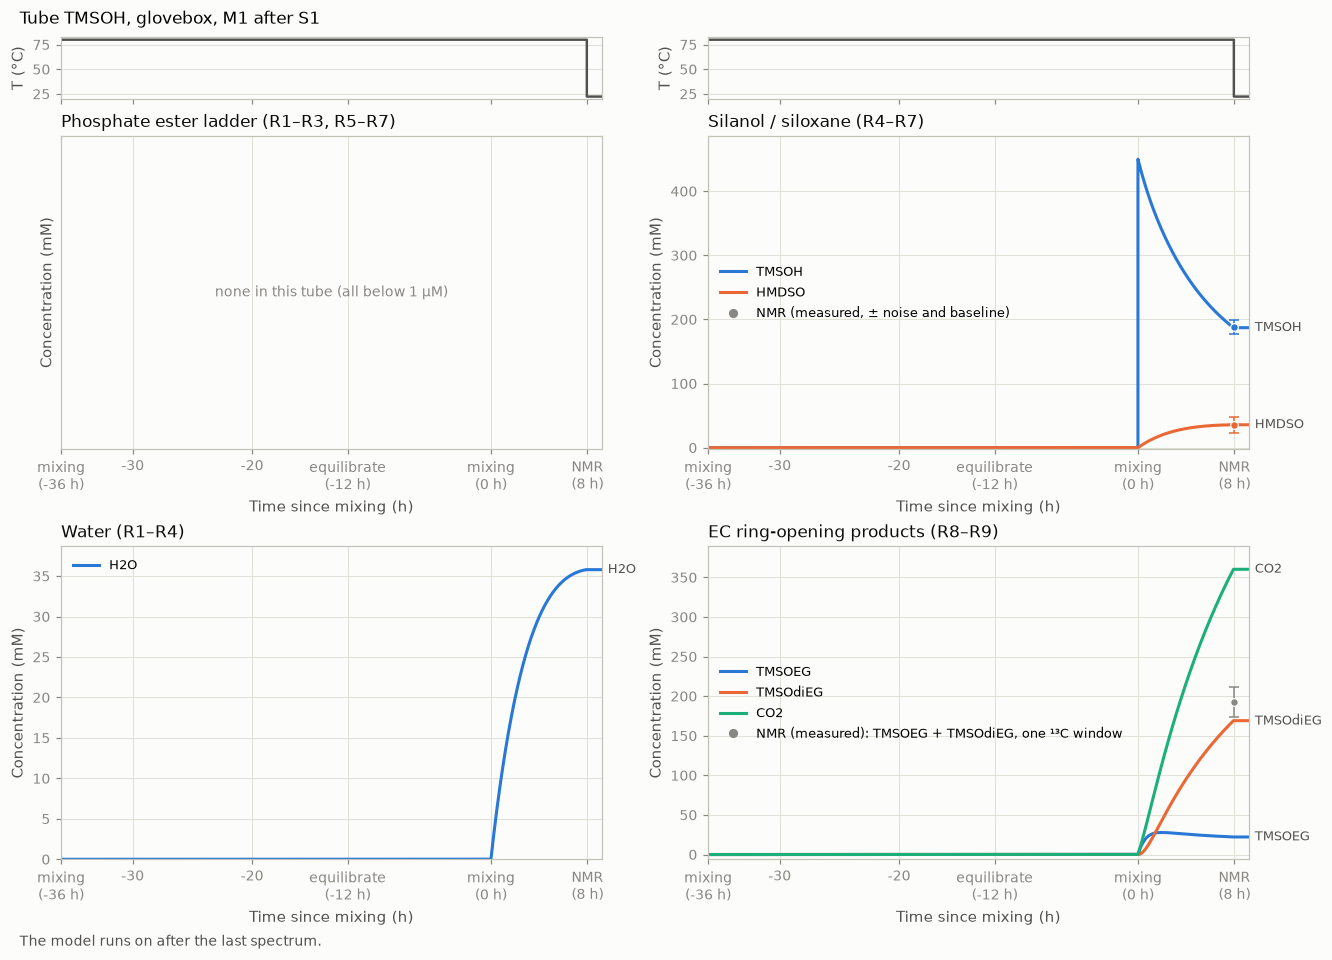

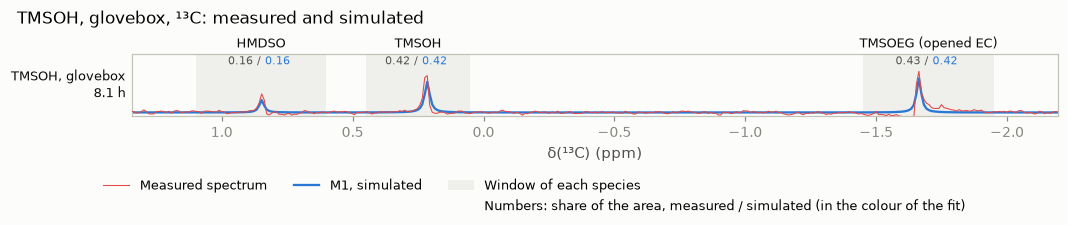

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
8.1,¹³C,TMSOH,188.0,187.2,-0.7,30.27,-0.0
8.1,¹³C,HMDSO,72.3,71.6,-0.7,28.38,-0.0
8.1,¹³C,TMSOEG (opened EC),192.2,191.2,-1.0,34.48,-0.0


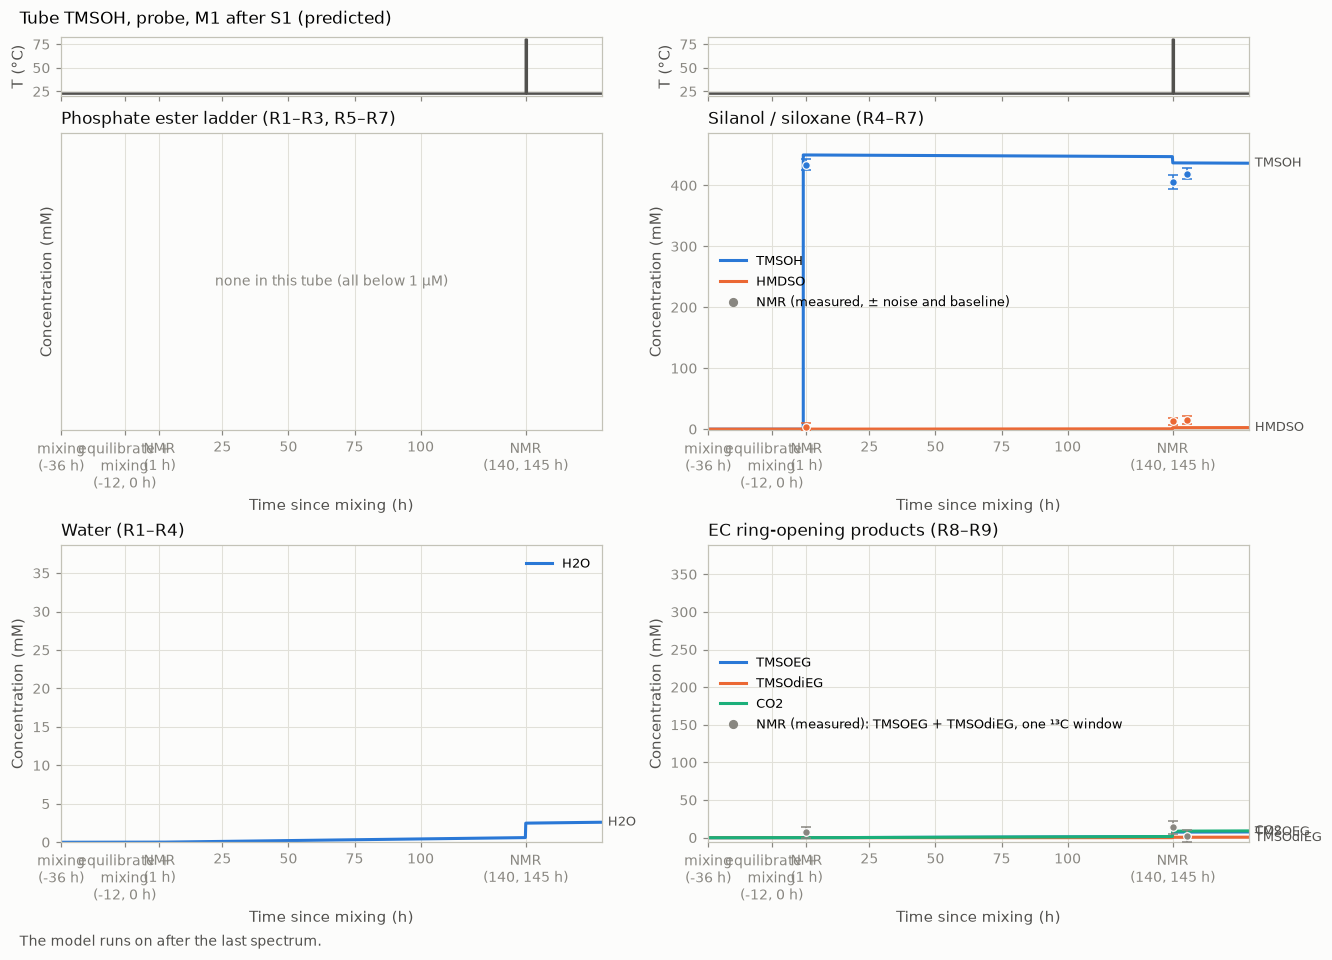

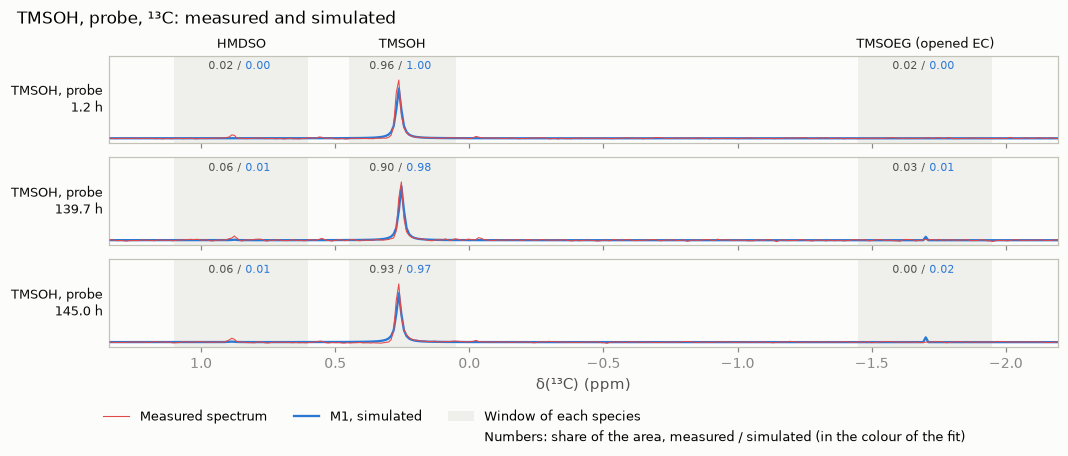

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
1.2,¹³C,TMSOH,433.8,450.0,+16.2,65.68,+0.2
1.2,¹³C,HMDSO,7.7,0.0,-7.6,17.54,-0.4
1.2,¹³C,TMSOEG (opened EC),7.4,0.0,-7.3,15.42,-0.5
139.7,¹³C,TMSOH,405.6,441.0,+35.4,61.87,+0.6
139.7,¹³C,HMDSO,25.2,3.5,-21.7,17.36,-1.3
139.7,¹³C,TMSOEG (opened EC),13.9,5.5,-8.4,15.94,-0.5
145.1,¹³C,TMSOH,419.1,436.9,+17.7,63.57,+0.3
145.1,¹³C,HMDSO,28.6,5.0,-23.6,18.85,-1.3
145.1,¹³C,TMSOEG (opened EC),2.2,8.1,+5.9,15.60,+0.4


S1 at 1 h: the four E_0 (g, eV)
	hydrolysis: 1.700  not fitted (held off)
	transfer: 1.500  not fitted (held off)
	condensation: 1.184  FITTED
	solvent attack: 1.223  FITTED
Now we try to stimate different escenarios for the first NMR reading


reading,10 min,1 h,8 h
S1: best fit,,,
condensation,1.184,1.184,1.184
solvent attack,1.223,1.223,1.223
χ²,0.001,0.001,0.001
worst miss,0.028,0.028,0.028


S1: χ² within 3.84 (eV),10 min,1 h,8 h
condensation,≤ 1.249,≤ 1.249,≤ 1.249
solvent attack,1.206–1.239,1.206–1.239,1.206–1.239


reading,10 min,1 h,8 h
"worst miss, predicted",,,
"TMSOH, probe",1.25,1.25,1.25


In [4]:
AGE_S1 = '1 h' # 10 min, 1 h or 8 h
show_concentrations_alike([(views[('S1', AGE_S1)], 'TMSOH, glovebox', f'{MAIN} after S1'),
                           (views[('S1', AGE_S1)], 'TMSOH, probe', f'{MAIN} after S1 (predicted)')], reading=AGE_S1)
theta = fits[('S1', AGE_S1)]['theta']
print(f"S1 at {AGE_S1}: the four E_0 (g, eV)")
for name, label in BARRIER_NAMES.items():
    print(f"\t{label}: {theta[name]:.3f}  " + ('FITTED' if name in STEPS['S1']['free'] else 'not fitted (held off)'))
print("Now we try to stimate different escenarios for the first NMR reading")
show_step_table('S1')
by_age(as_fitted[(as_fitted['step'] == 'S1') & (as_fitted['tube'] == 'TMSOH, probe')].pivot_table(index='tube', columns='scenario', values='max |z|')).round(2).rename_axis(index='worst miss, predicted')

### 2.2 S2: `TMSPa + TMSOH (A)` (transfer)

In [5]:
display(tabulate_step_reactions('S2'))

,reaction,family,10 min,1 h,8 h,set by
S2: g (eV),,,,,,
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis,off (1.70),off (1.70),off (1.70),held off: top of its range
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis,off (1.70),off (1.70),off (1.70),held off: top of its range
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis,off (1.70),off (1.70),off (1.70),held off: top of its range
N12,BMSPA + H₂O ⇌ H₃PO₄ + HMDSO,hydrolysis,off (1.70),off (1.70),off (1.70),held off: top of its range
N15,TMSPA + H₂O ⇌ MMSPA + HMDSO,hydrolysis,off (1.70),off (1.70),off (1.70),held off: top of its range
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,0.904,0.943,0.995,fitted in this step
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,0.904,0.943,0.995,fitted in this step
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,0.904,0.943,0.995,fitted in this step
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,1.184,1.184,1.184,S1 · glovebox


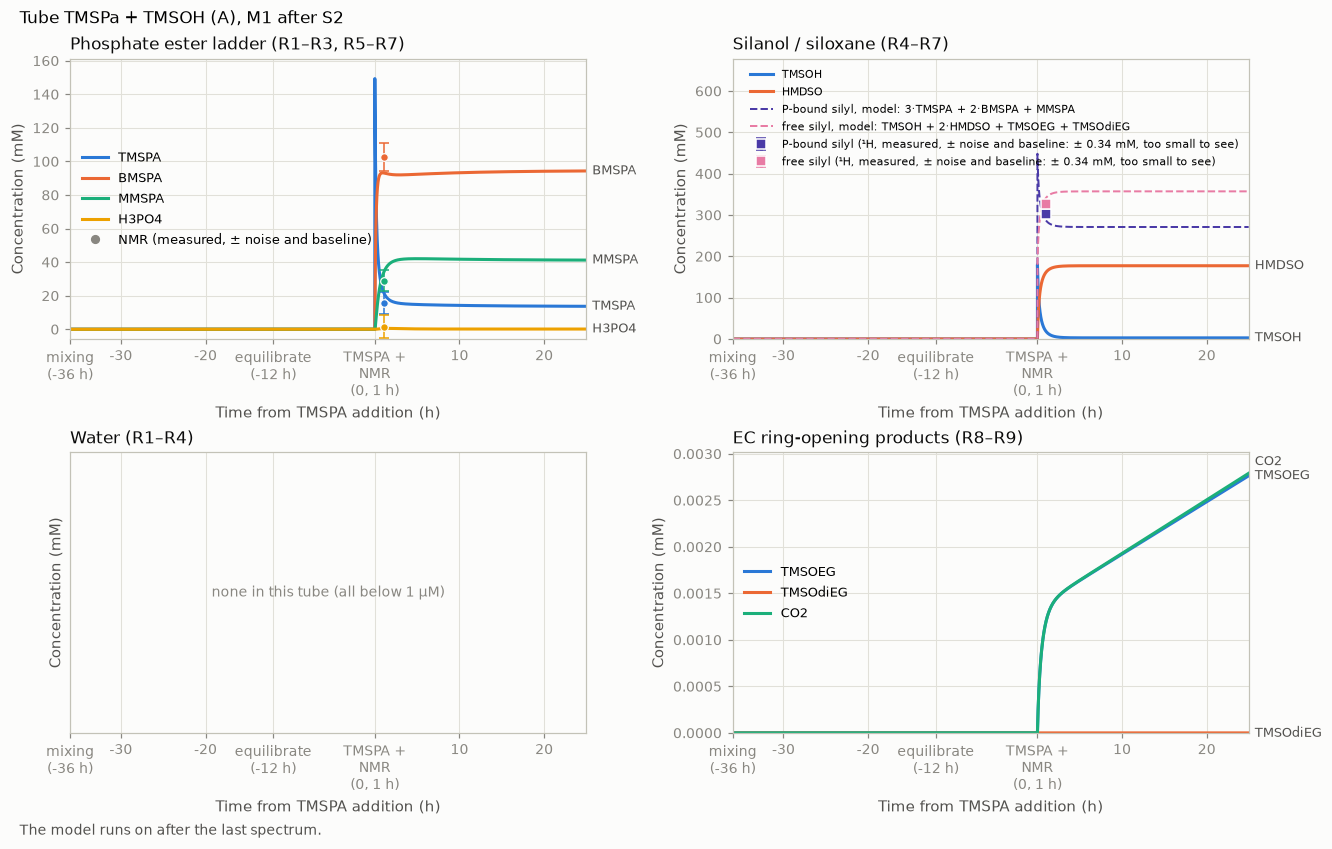

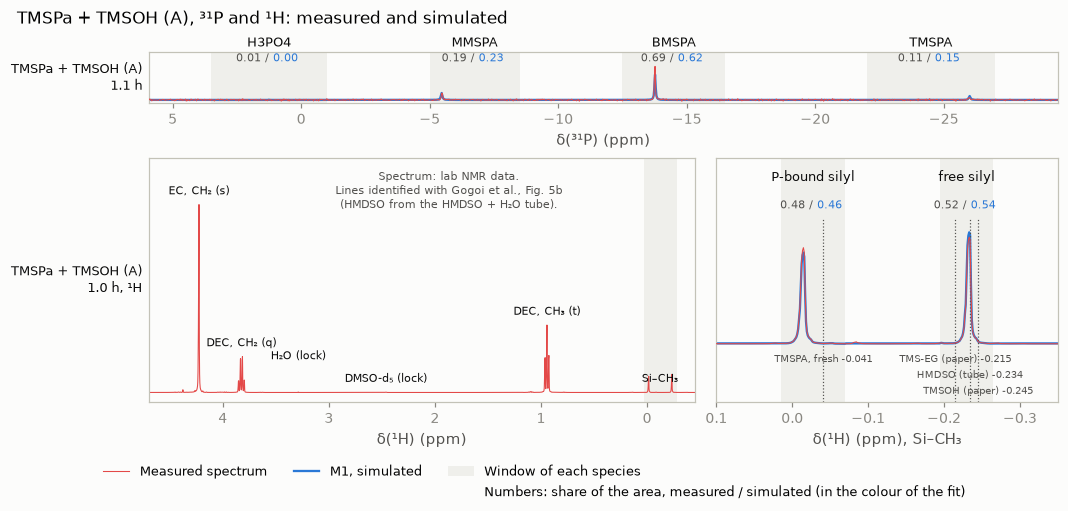

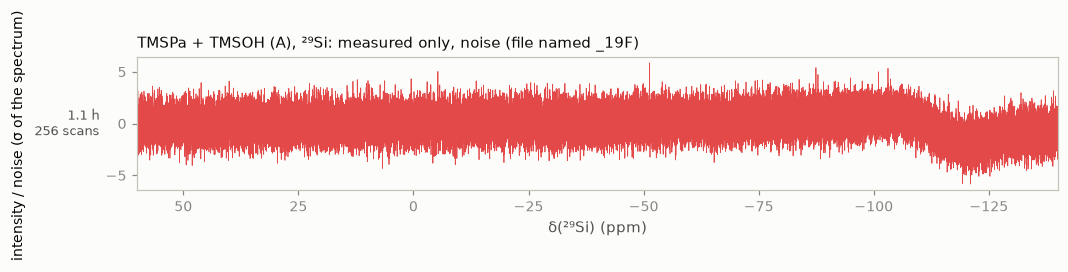

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
1.00,¹H,P-bound silyl (silyl groups),302.3,287.1,-15.2,15.12,-1.0
1.00,¹H,free silyl (silyl groups),326.0,341.2,+15.2,16.30,+0.9
1.06,³¹P,TMSPA,15.7,21.8,+6.0,6.65,+0.9
1.06,³¹P,BMSPA,102.7,93.1,-9.6,9.87,-1.0
1.06,³¹P,MMSPA,29.0,34.0,+5.0,6.44,+0.8
1.06,³¹P,H3PO4,1.5,0.5,-1.0,7.00,-0.1


reading,10 min,1 h,8 h
S2: best fit,,,
transfer,0.904,0.943,0.995
χ²,1.808,1.791,1.770
worst miss,0.976,0.971,0.964


S2: χ² within 3.84 (eV),10 min,1 h,8 h
transfer,≤ 0.917,≤ 0.956,≤ 1.008


reading,10 min,1 h,8 h
transfer (eV): hydrolysis off (S2) and on (S2b),,,
S2,0.904,0.9431,0.9946
S2b,0.904,0.9431,0.9946


In [6]:
AGE_S2 = '1 h' 
# The other two spectra of the ³¹P session of tube A (15 May 2023); neither is fitted. 1: shown, 0: not
SHOW_1H = 1      # ¹H, 3.7 min before the ³¹P: points in C(t), a row under the ³¹P spectrum, rows in the table
SHOW_29SI = 1    # ²⁹Si (the file is named _19F; its header says 29Si), 3.3 min after the ³¹P: noise only, no line
show_concentrations_with_extra_nmr(views[('S2', AGE_S2)], 'TMSPa + TMSOH (A)', f'{MAIN} after S2', reading=AGE_S2,
                                   with_1h=SHOW_1H, with_29si=SHOW_29SI)

show_step_table('S2')
by_age(summary[summary['step'].isin(['S2', 'S2b'])].pivot(index='step', columns='scenario', values='g transfer')).round(4).rename_axis(
    'transfer (eV): hydrolysis off (S2) and on (S2b)', axis=0)

### 2.3 S3: `TMSPa alone` (hydrolysis)

In [7]:
tabulate_step_reactions('S3')

,reaction,family,10 min,1 h,8 h,set by
S3: g (eV),,,,,,
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis,1.062,1.102,1.143,fitted in this step
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis,1.062,1.102,1.143,fitted in this step
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis,1.062,1.102,1.143,fitted in this step
N12,BMSPA + H₂O ⇌ H₃PO₄ + HMDSO,hydrolysis,1.062,1.102,1.143,fitted in this step
N15,TMSPA + H₂O ⇌ MMSPA + HMDSO,hydrolysis,1.062,1.102,1.143,fitted in this step
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,1.184,1.184,1.184,S1 · glovebox


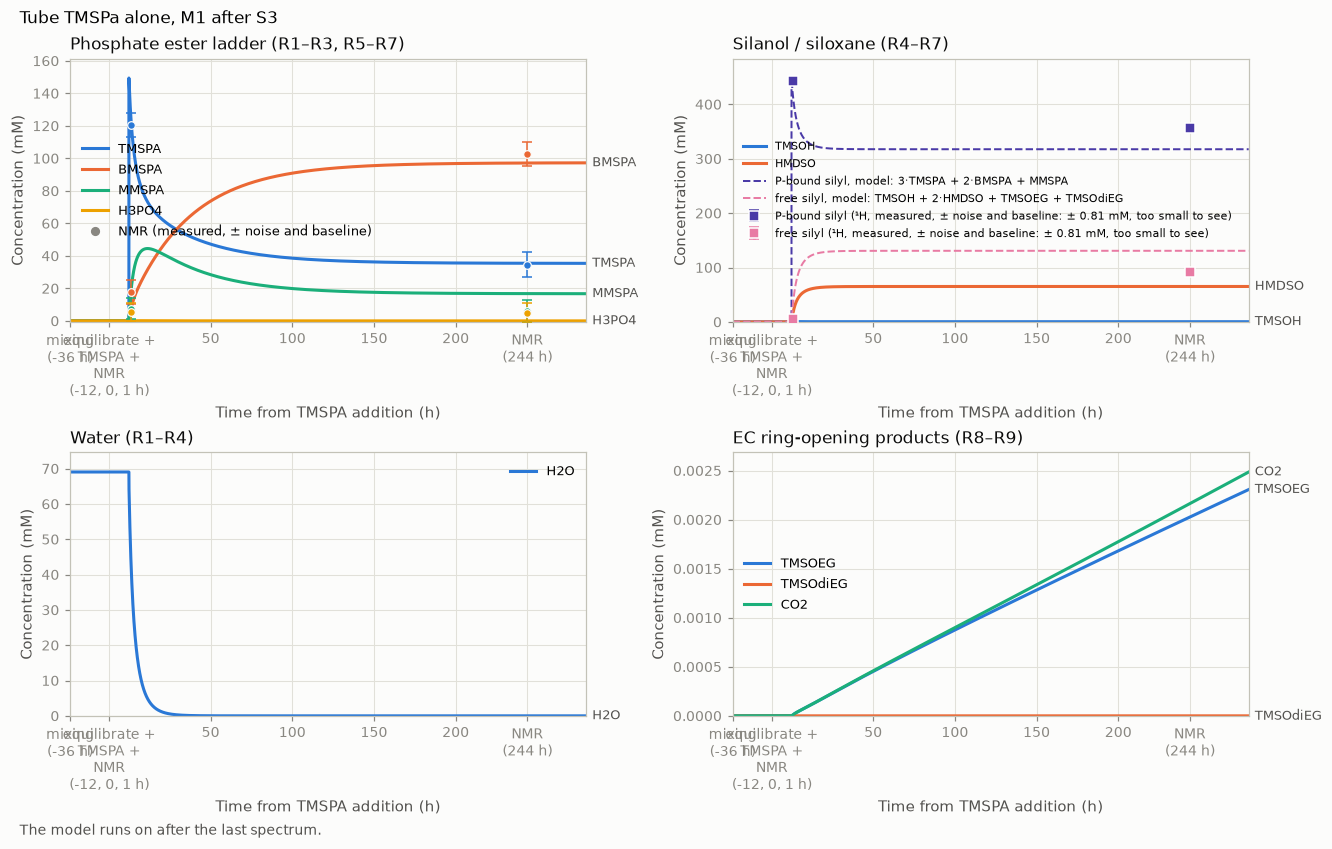

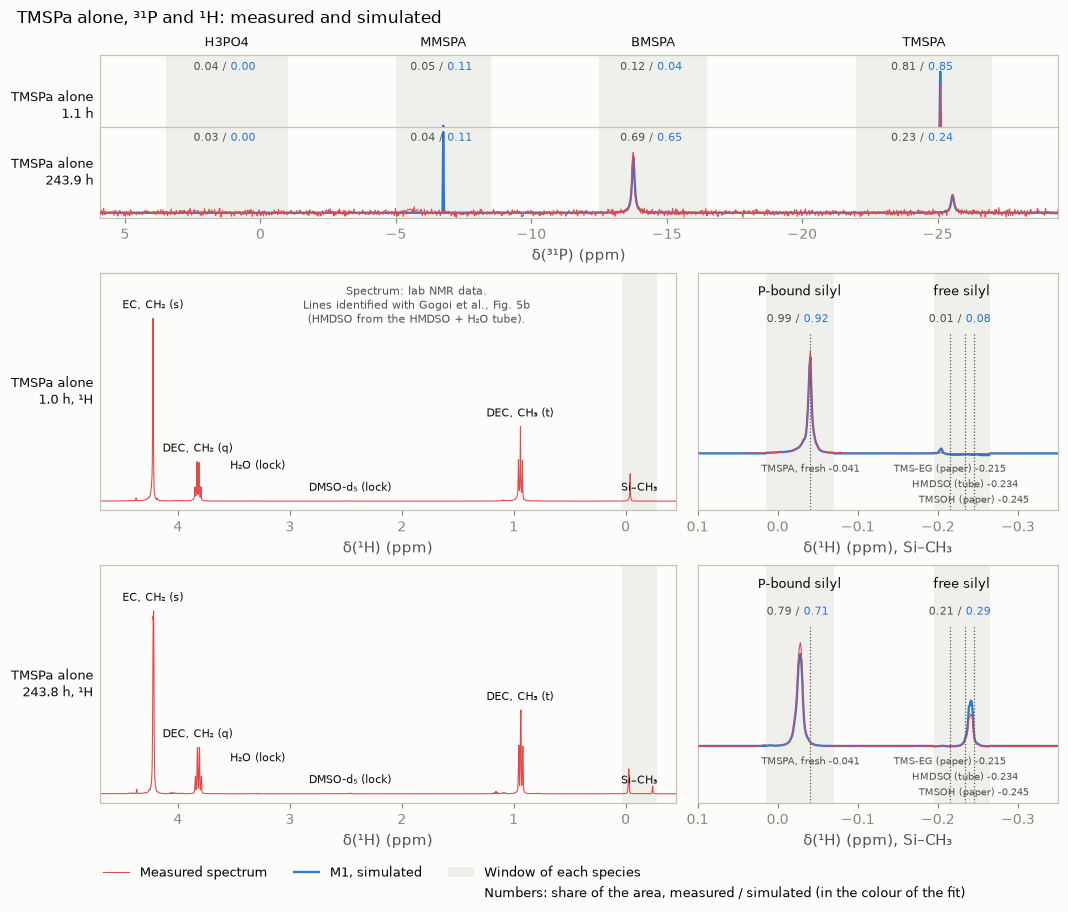

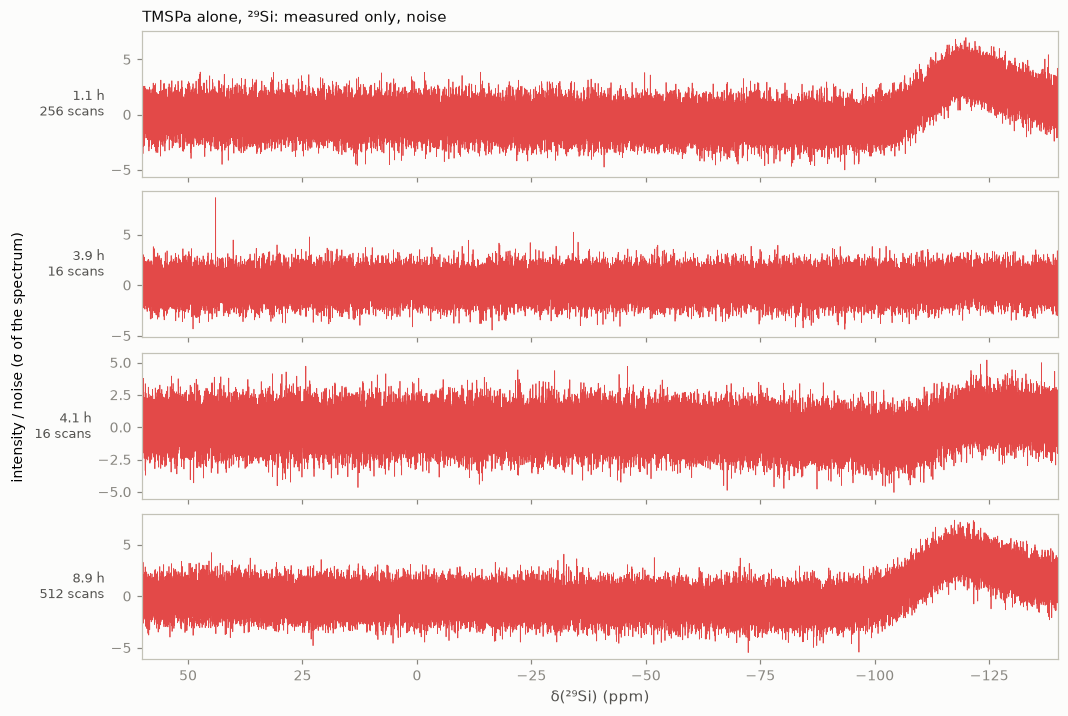

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
1.00,¹H,P-bound silyl (silyl groups),443.6,412.3,-31.3,22.19,-1.4
1.00,¹H,free silyl (silyl groups),4.7,36.0,+31.3,4.55,+6.9
1.05,³¹P,TMSPA,120.5,127.7,+7.1,9.76,+0.7
1.05,³¹P,BMSPA,17.7,6.0,-11.7,7.46,-1.6
1.05,³¹P,MMSPA,7.4,15.7,+8.3,6.67,+1.2
1.05,³¹P,H3PO4,5.4,0.0,-5.4,5.59,-1.0
243.84,¹H,P-bound silyl (silyl groups),356.3,317.5,-38.8,17.82,-2.2
243.84,¹H,free silyl (silyl groups),92.0,130.8,+38.8,4.61,+8.4
243.88,³¹P,TMSPA,34.6,35.5,+0.9,7.70,+0.1
243.88,³¹P,BMSPA,102.8,97.1,-5.6,8.84,-0.6


reading,10 min,1 h,8 h
S3: best fit,,,
hydrolysis,1.062,1.102,1.143
χ²,6.730,6.773,36.185
worst miss,1.564,1.563,4.420


S3: χ² within 3.84 (eV),10 min,1 h,8 h
hydrolysis,1.043–1.097,1.084–1.137,1.129–1.159


In [8]:
AGE_S3 = '1 h'
# The other spectra of the two ³¹P sessions of TMSPa alone (15 and 25 May 2023); none is fitted. 1: shown, 0: not
SHOW_1H = 1      # ¹H, 3 min before the first ³¹P and 2 min before the second: points in C(t), rows under the ³¹P, rows in the table
SHOW_29SI = 1    # four ²⁹Si of the first session, from 3 min to 7.9 h after its ³¹P: noise only, no line
show_concentrations_with_extra_nmr(views[('S3', AGE_S3)], 'TMSPa alone', f'{MAIN} after S3', reading=AGE_S3,
                                   with_1h=SHOW_1H, with_29si=SHOW_29SI)
show_step_table('S3')

### 2.4 S4: `0.5 % H2O` (hydrolysis again)

**The question:** does `0.5 % H2O` ask for the hydrolysis that `TMSPa alone` gave?

- **First figure:** the prediction, with the barriers of S3. **Second figure:** S4, hydrolysis fitted to this tube alone, the other barriers as in S3.
- **Tables:** hydrolysis from S3 and from S4 with their ranges; the worst miss of both tubes with each hydrolysis.

In [9]:
tabulate_step_reactions('S4')

,reaction,family,10 min,1 h,8 h,set by
S4: g (eV),,,,,,
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis,1.246,1.255,1.265,fitted in this step
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis,1.246,1.255,1.265,fitted in this step
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis,1.246,1.255,1.265,fitted in this step
N12,BMSPA + H₂O ⇌ H₃PO₄ + HMDSO,hydrolysis,1.246,1.255,1.265,fitted in this step
N15,TMSPA + H₂O ⇌ MMSPA + HMDSO,hydrolysis,1.246,1.255,1.265,fitted in this step
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,1.184,1.184,1.184,S1 · glovebox


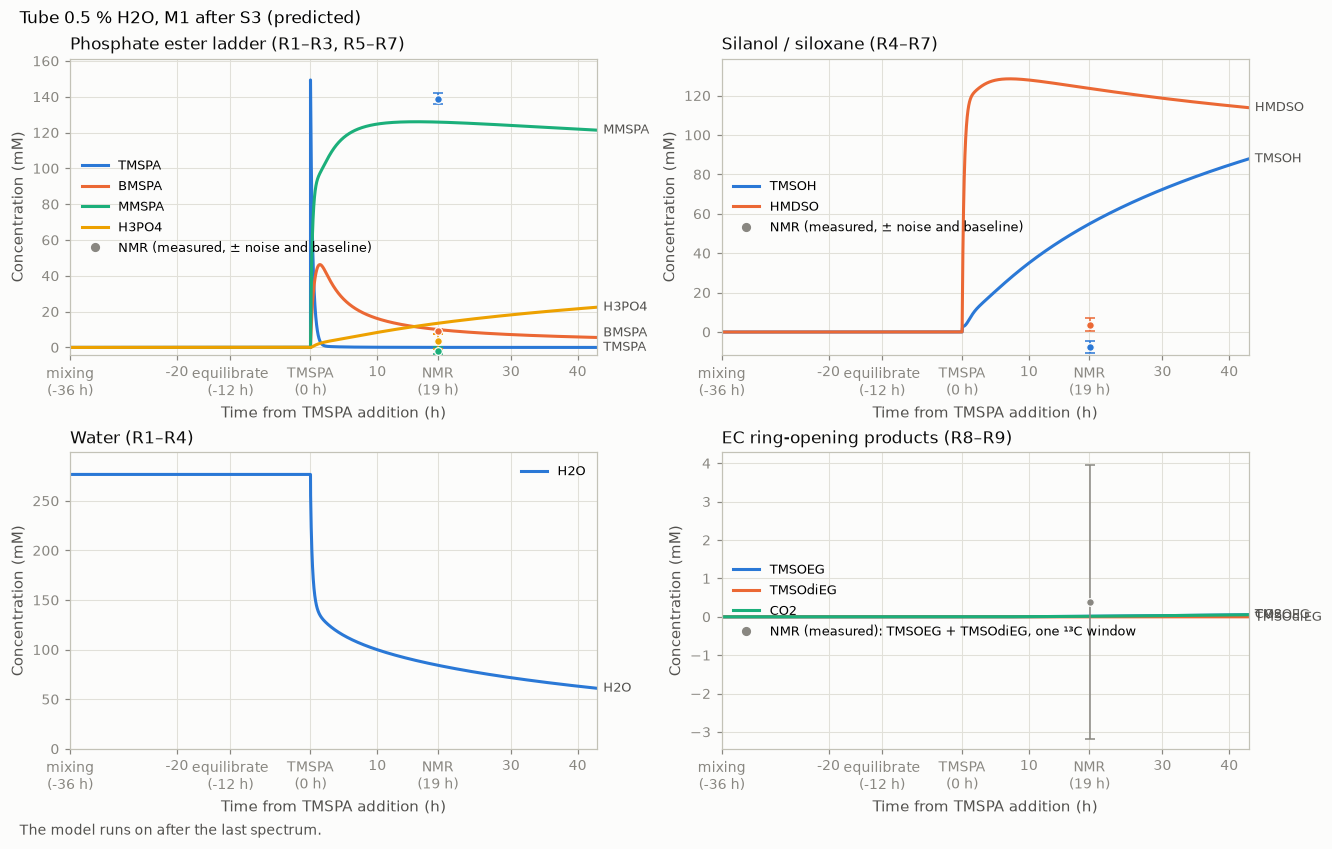

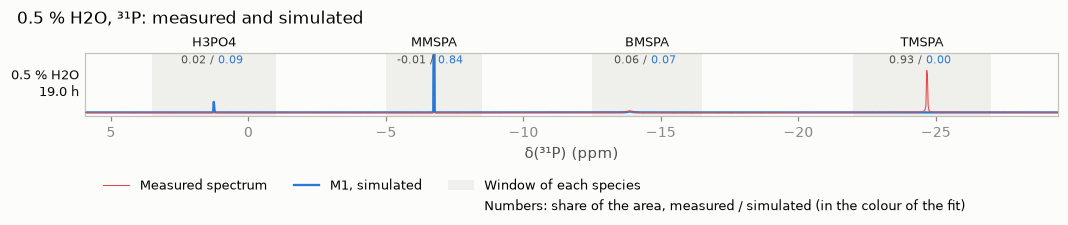

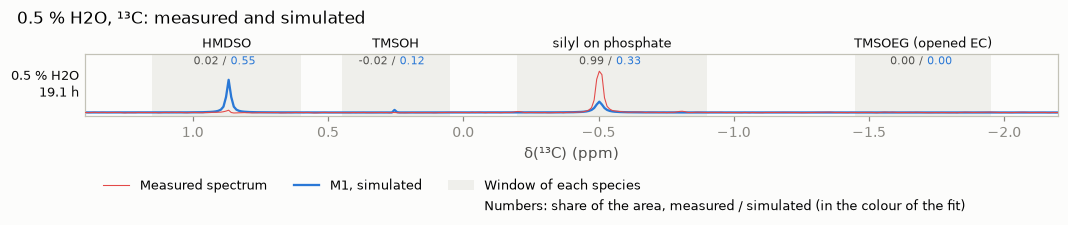

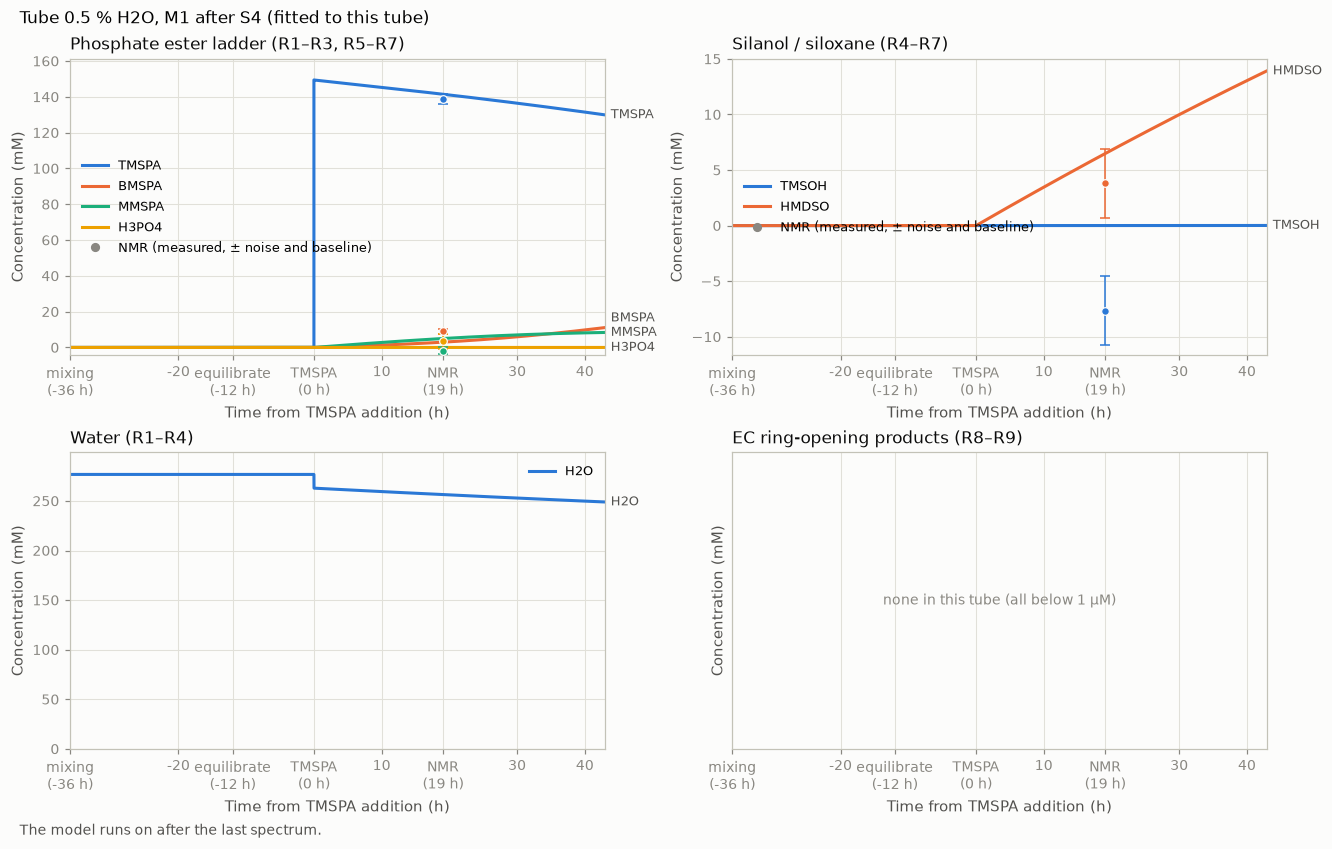

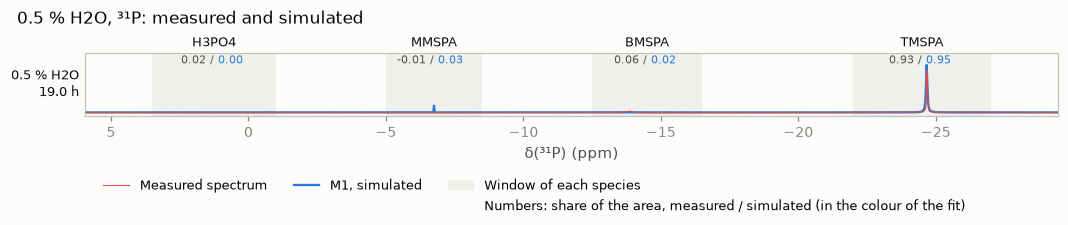

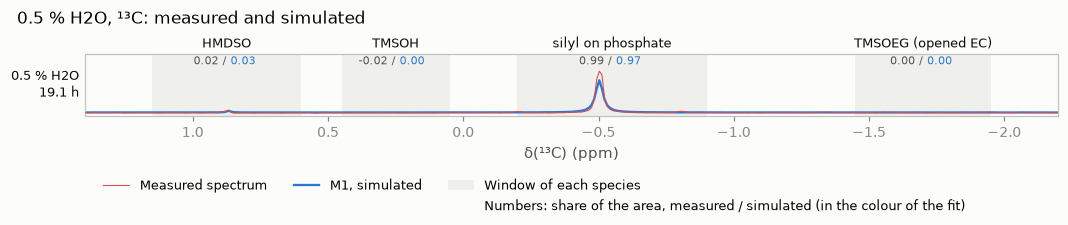

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
19.0,³¹P,TMSPA,139.0,141.5,+2.5,7.53,+0.3
19.0,³¹P,BMSPA,9.0,3.0,-6.0,2.03,-3.0
19.0,³¹P,MMSPA,-1.9,5.0,+6.9,2.47,+2.8
19.0,³¹P,H3PO4,3.4,0.0,-3.4,4.41,-0.8
19.1,¹³C,TMSOH,-7.6,0.0,+7.6,13.81,+0.6
19.1,¹³C,HMDSO,7.6,13.0,+5.4,14.82,+0.4
19.1,¹³C,TMSOEG (opened EC),0.4,0.0,-0.4,13.92,-0.0
19.1,¹³C,silyl on phosphate,445.9,435.3,-10.7,67.14,-0.2


hydrolysis (eV),10 min,1 h,8 h
S3,1.062,1.102,1.143
S4,1.246,1.255,1.265
"S3, χ² within 3.84",1.043–1.097,1.084–1.137,1.129–1.159
"S4, χ² within 3.84",1.232–1.336,≥ 1.237,≥ 1.246


reading                               10 min   1 h   8 h
worst miss of with the hydrolysis of                    
0.5 % H2O     S3                        51.8  47.0  40.1
              S4                         3.0   3.6   3.7
TMSPa alone   S3                         1.6   1.6   4.4
              S4                        11.2  12.7  13.5

In [10]:
# The reading drawn here. Computed: '10 min', '1 h', '8 h' (READINGS); the text below quotes 10 min
AGE_S4 = '10 min'
show_concentrations(views[('S3', AGE_S4)], '0.5 % H2O', f'{MAIN} after S3 (predicted)', table=False, reading=AGE_S4)
show_concentrations(views[('S4', AGE_S4)], '0.5 % H2O', f'{MAIN} after S4 (fitted to this tube)', reading=AGE_S4)
hydrolysis = intervals[intervals['parameter'] == 'g hydrolysis'].assign(structure=MAIN, tag='')
best = by_age(summary[summary['step'].isin(['S3', 'S4'])].pivot(index='step', columns='scenario', values='g hydrolysis')).round(3)
spans = pd.concat([tables.format_interval_table(hydrolysis[hydrolysis['step'] == step], MAIN, scenarios=READINGS)
                   .rename(index={'g hydrolysis': f'{step}, χ² within 3.84'}) for step in ('S3', 'S4')]).rename(columns=AGES)
display(pd.concat([best.astype(str), spans]).rename_axis('hydrolysis (eV)', axis=1))
cross = as_fitted[as_fitted['tube'].isin(['0.5 % H2O', 'TMSPa alone']) & as_fitted['step'].isin(['S3', 'S4'])]
by_age(cross.pivot_table(index=['tube', 'step'], columns='scenario', values='max |z|')).round(1).rename_axis(index=['worst miss of', 'with the hydrolysis of'])

**What we see**

- **The prediction fails:** with the hydrolysis of S3 (first figure), TMSPA is gone within an hour of mixing and the tube sits at MMSPA by its spectrum (about 125 mM simulated, none measured; 139 mM of TMSPA measured). Worst miss 52, 47 and 40 at 10 min, 1 h and 8 h.
- **Fitted alone (second figure), it asks for a slower hydrolysis:** 1.246, 1.255 and 1.265 eV, about 0.15 eV above S3. TMSPA then falls slowly (142 mM simulated at 19 h, 139 measured). The ranges do not overlap with those of S3.
- **Even alone it fits only at 10 min** (worst miss 3.0; 3.6 and 3.7 at 1 h and 8 h, BMSPA).
- **With that hydrolysis `TMSPa alone` fails** (11 to 14). With M1, one hydrolysis barrier cannot give both tubes. §4.3 shows that the reference model can.
- **A choice behind this:** the water of `TMSPa alone` is declared (65.6 mM), not measured. With another amount S3 would give another hydrolysis.

### 2.5 S5: `2 % H2O` (the computed energies)

**The question:** with the barriers of S3, does M1 give `2 % H2O`, under either reading of its history?

- Nothing is fitted. **First figure:** the tube as this project reads it; **second:** as the reference model reads it (barriers of S3 at 10 min in both).
- **Table:** χ² and worst miss under the two readings and the three ages.

In [11]:
tabulate_step_reactions('S5')

,reaction,family,10 min,1 h,8 h,set by
S5: g (eV),,,,,,
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis,1.062,1.102,1.143,S3 · TMSPa alone
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis,1.062,1.102,1.143,S3 · TMSPa alone
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis,1.062,1.102,1.143,S3 · TMSPa alone
N12,BMSPA + H₂O ⇌ H₃PO₄ + HMDSO,hydrolysis,1.062,1.102,1.143,S3 · TMSPa alone
N15,TMSPA + H₂O ⇌ MMSPA + HMDSO,hydrolysis,1.062,1.102,1.143,S3 · TMSPa alone
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,0.904,0.943,0.995,S2 · tube A
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,1.184,1.184,1.184,S1 · glovebox


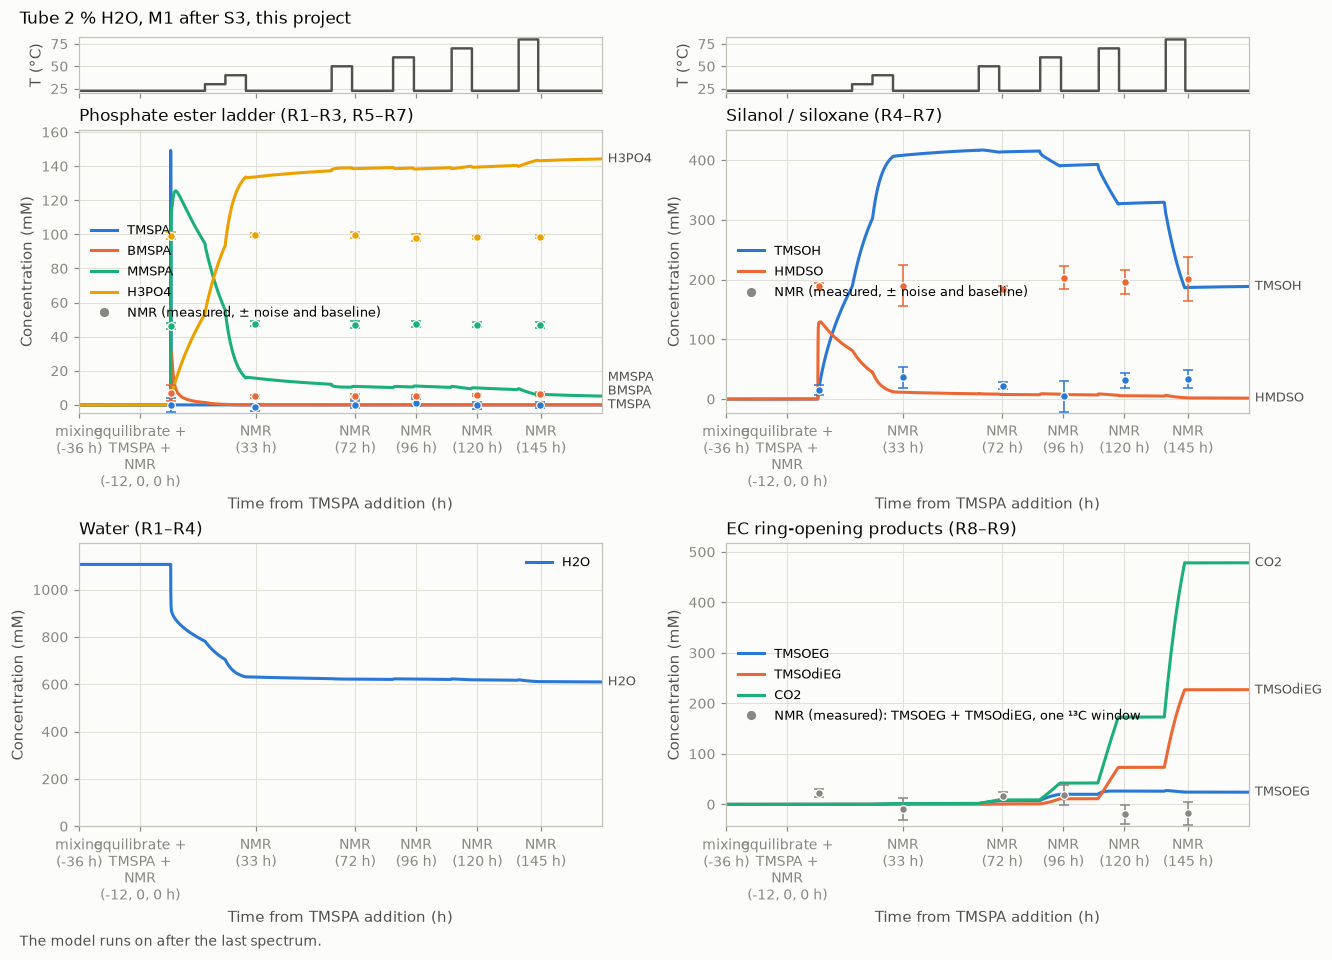

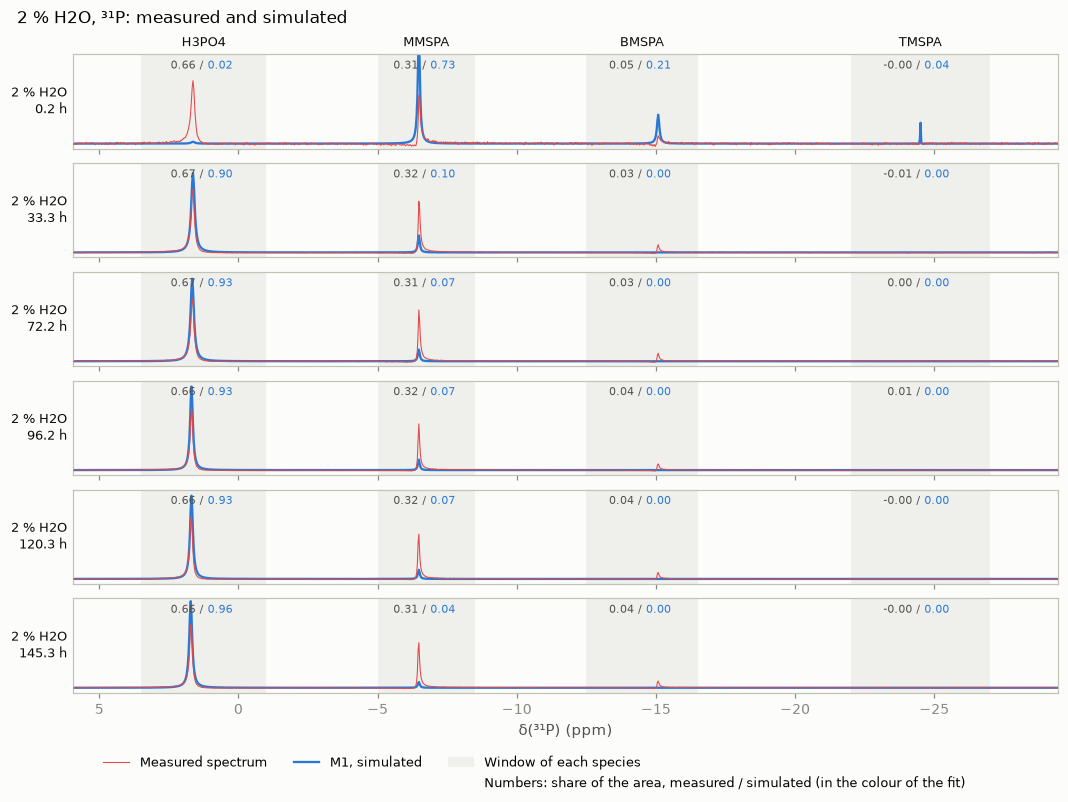

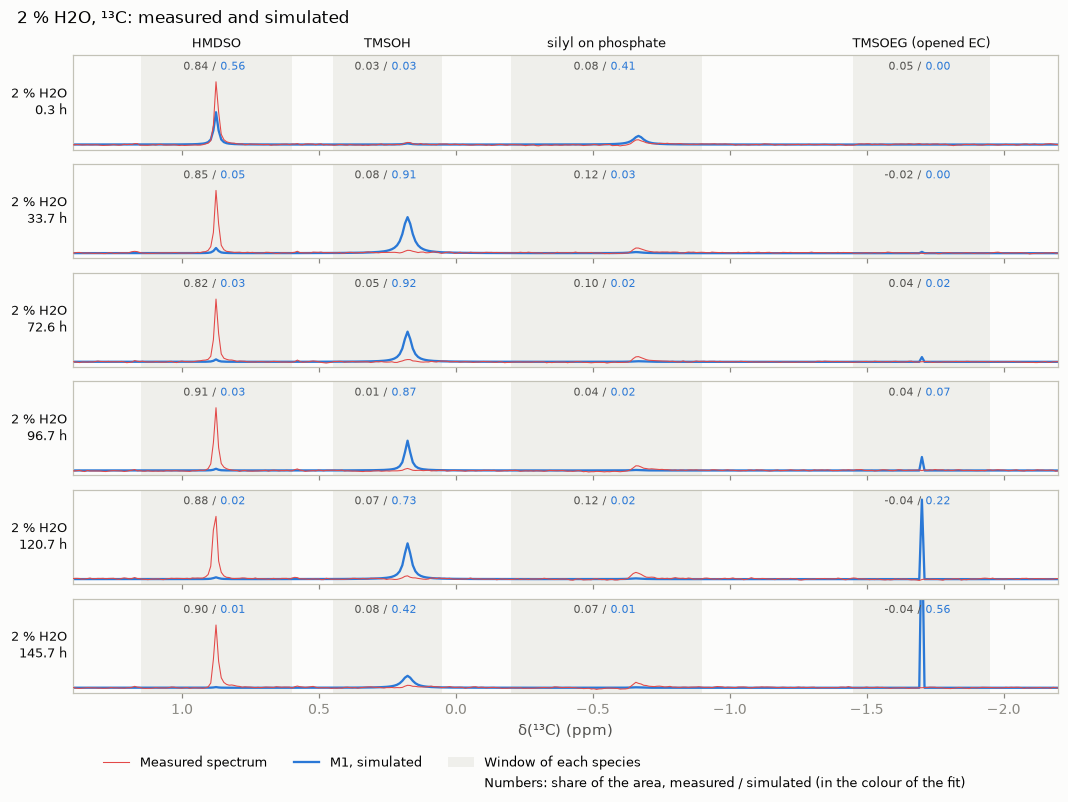

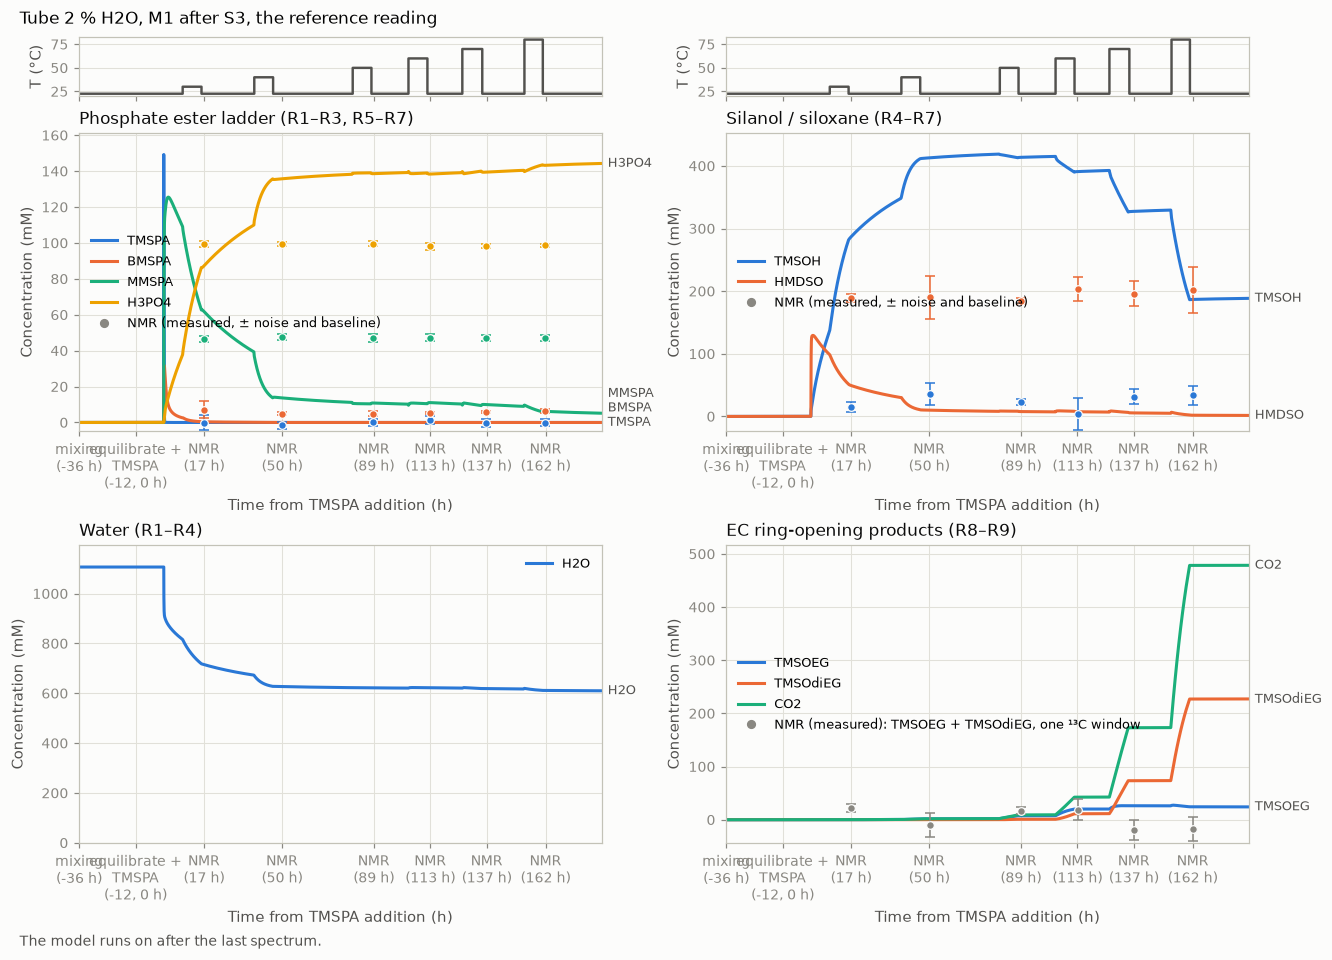

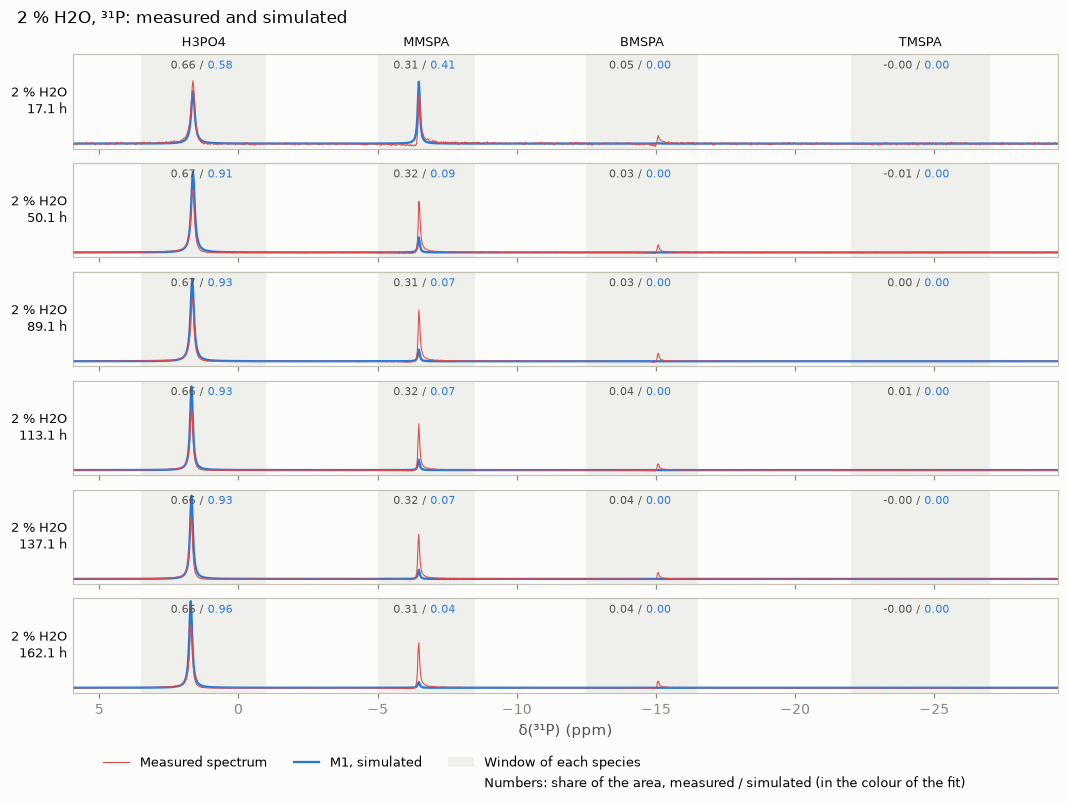

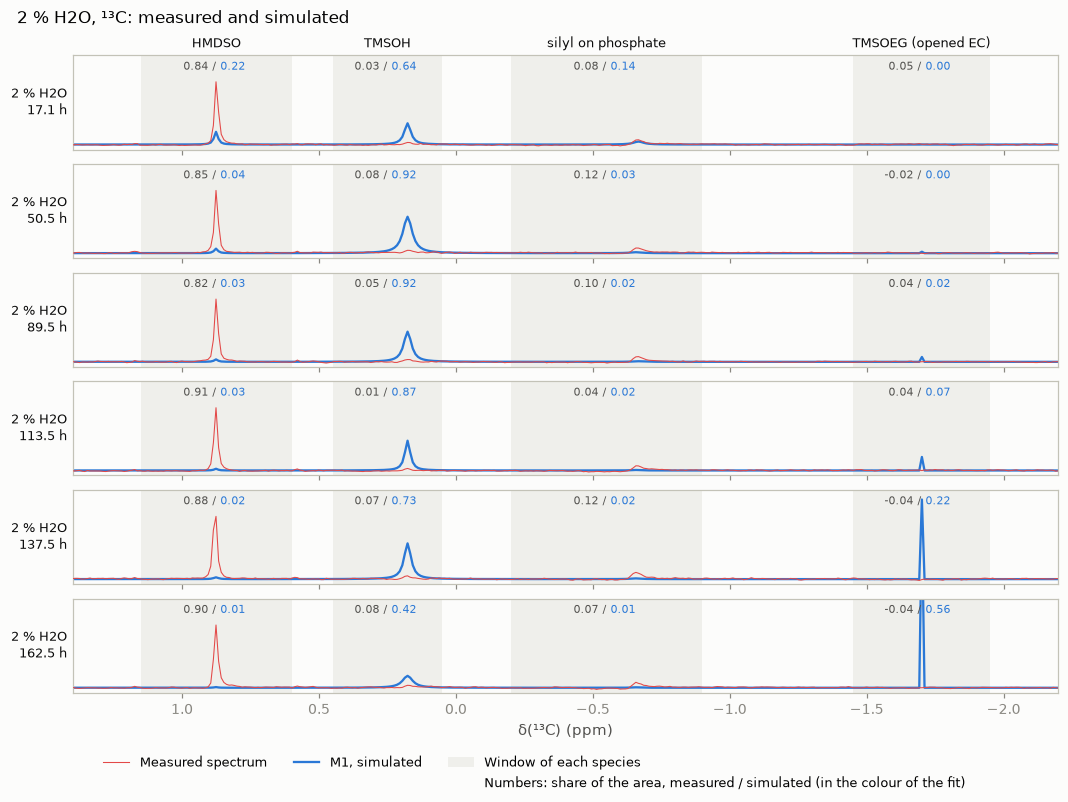

χ²                  worst miss              
scenario                   1 h  10 min      8 h        1 h 10 min    8 h
variant                                                                 
the reference reading  10520.1  1744.3  30079.0       66.4   27.0  114.2
this project           12751.0  5307.2  30832.3       73.4   51.4  116.0

In [12]:
# The reading drawn here. Computed: '10 min', '1 h', '8 h' (READINGS); the text below quotes 10 min
AGE_S5 = '10 min'
show_concentrations(views[('S5', AGE_S5)], '2 % H2O', f'{MAIN} after S3, this project', table=False, reading=AGE_S5)
show_concentrations(evaluate_fit(fits[('S5', AGE_S5)], observables, overrides=REF_HISTORY), '2 % H2O', f'{MAIN} after S3, the reference reading',
                    note='First spectrum after 8 h at room temperature, 8 h at 30 °C and 1 h of acquisition (the reference reading).', table=False, reading=AGE_S5)
two_way = scores[(scores['step'] == 'S5') & (scores['tube'] == '2 % H2O')].pivot(index='variant', columns='scenario', values=['chi2', 'max |z|'])
two_way.rename(index={'as fitted': 'this project', REF_READING: 'the reference reading'}, columns={'chi2': 'χ²', 'max |z|': 'worst miss'}).round(1)

**What we see**

- **Under either reading `2 % H2O` is not described.** χ² 5 307, 12 751 and 30 832 (worst miss 51, 73, 116) as this project reads the tube; 1 744, 10 520 and 30 079 (27, 66, 114) as the reference model reads it.
- **The reference reading helps the first spectrum only:** 17 h after mixing, 8 h of it at 30 °C, the phosphate has moved towards H₃PO₄. Read as this project reads it, the first spectrum comes minutes after mixing and M1 still shows mostly MMSPA there.
- **After that both readings end the same way, away from the measurement:**
  - the phosphate runs on to H₃PO₄ (about 140 mM against 99 measured), with too little MMSPA (about 10 against 47 mM);
  - the silyl groups stay as TMSOH (about 400 mM through most of the ramp, against about 30 measured) where the tube holds HMDSO;
  - from 70 °C on that TMSOH opens the solvent (about 480 mM of CO₂ and 230 mM of TMSOdiEG after 80 °C), which the spectra do not show.
- **This is the end state of the computed energies,** the same failure as when M1 is fitted to every tube at once (rev07). No barrier changes where a reaction stops.

---
## 3. The steps in one table

**The question:** after each step, which tubes does M1 describe, fitted or predicted, and with which barriers?

- **First table:** the worst miss of each tube (rows) with the barriers of each step (columns), under the three readings. 3 or less: described.
- **Second table:** the barriers M1 ends with after S1–S3, against M1 fitted to every tube at once (seventh fit), both at 10 min, the only reading the two runs share.

In [13]:
worst = as_fitted.pivot_table(index=['scenario', 'tube'], columns='step', values='max |z|').reindex(columns=list(STEPS)).rename(columns=label_step)
worst = worst.reindex(pd.MultiIndex.from_product([READINGS, list(TUBE_NAMES)])).rename(index=TUBE_NAMES, level=1).rename_axis(['reading', 'worst miss of'])
display(worst.style.format(precision=1).map(lambda v: 'font-weight: bold' if v > 3.0 else ''))
seventh = json.loads((REPO / 'notebooks' / 'results' / '05_fit7' / 'fits' / 'M1__10_min.json').read_text())
pd.DataFrame({'every tube at once (seventh fit)': {BARRIER_NAMES[k]: seventh['theta'][k] for k in BARRIER_NAMES},
              'one tube at a time (S1–S3)': {BARRIER_NAMES[k]: fits[('S3', '10 min')]['theta'][k] for k in BARRIER_NAMES}}).round(3).rename_axis('g at 10 min (eV)', axis=1)

g at 10 min (eV),every tube at once (seventh fit),one tube at a time (S1–S3)
hydrolysis,0.800,1.062
transfer,0.902,0.904
condensation,1.130,1.184
solvent attack,1.297,1.223


**What we see**

- **After S3, four tubes are described with four barriers** (glovebox, probe, tube A, `TMSPa alone`) at 10 min and at 1 h. `0.5 % H2O` and `2 % H2O` are not.
- **S4 swaps one failure for another:** `0.5 % H2O` is reached, `TMSPa alone` is lost.
- **Compared with every tube at once:** transfer is the same (0.904 against 0.902 eV): tube A sets it either way. The other three move once `2 % H2O`, which M1 cannot describe, no longer pulls on them: hydrolysis 1.06 eV instead of 0.80 (the lowest value allowed), solvent attack 1.22 instead of 1.30, condensation 1.18 instead of 1.13.

---
## 4. Our M1 and the reference model

**The question:** the reference model is almost the same as M1, and its curves come close to the NMR where ours do not. Is this code doing something wrong?

### 4.1 What is the same and what differs

| | The reference model (network notebook, EC:DEC linear) | M1 here |
|---|---|---|
| Reactions | R1–R9 + N10–N15, generated from the database | the same 15 |
| Reaction energies | database: DFT in the gas phase + MD solvation, EC and DEC mixed linearly | the same values (R1 −0.253 eV = −5.83 kcal/mol, …) |
| Rate constant | k = (k_BT/h) exp(−ΔG‡/k_BT) | the same |
| **Barrier rule** | ΔG‡ = E₀ for a downhill step, E₀ + ΔG uphill | Marcus: ΔG‡ = g (1 + ΔG/4g)², **below g for a downhill step** |
| **Barrier classes** | R1 alone; R2/R3; R4; R5–R7; R8/R9; **N10–N15 all "other"** | one hydrolysis for R1–R3 **with N12 and N15**; R4; R5–R7; R8/R9; N10, N11, N13, N14 at 1.15 eV |
| **Barrier values (eV)** | R1 1.24 (a lower bound), R2/R3 0.96, R4 0.96, R5–R7 0.92, R8/R9 1.40 (a lower bound), other 1.15: fitted to NMR | fitted tube by tube (§2) |
| **Data** | the ³¹P of `2 % H2O` | six tubes, ³¹P and ¹³C |
| **Time of the `2 % H2O` spectra** | after the holds: the first after 8 h at 20 °C and 8 h at 30 °C | the first before any heating, 10 min to 8 h after mixing |
| Room temperature | 20 °C | as recorded, 22–23 °C |

The rows in bold are the differences. The next three parts test them one by one.

### 4.2 Same inputs, same results?

**The test:** its barriers, rule and classes, given to this code and run through its bench protocol (EC:DEC 1:1 with 2 vol% water, then 5 vol% TMSPA at `t = 0`, 8 h holds at 20, 30 … 80 °C, each followed by 1 h at 20 °C for the spectrum). Then the same protocol with the barriers of S3.

- **Figures:** C(t) through the protocol, the reference model and then ours.
- **Table:** after each hold, the phosphorus as shares (³¹P) and the silyl groups as shares (¹³C), for both.

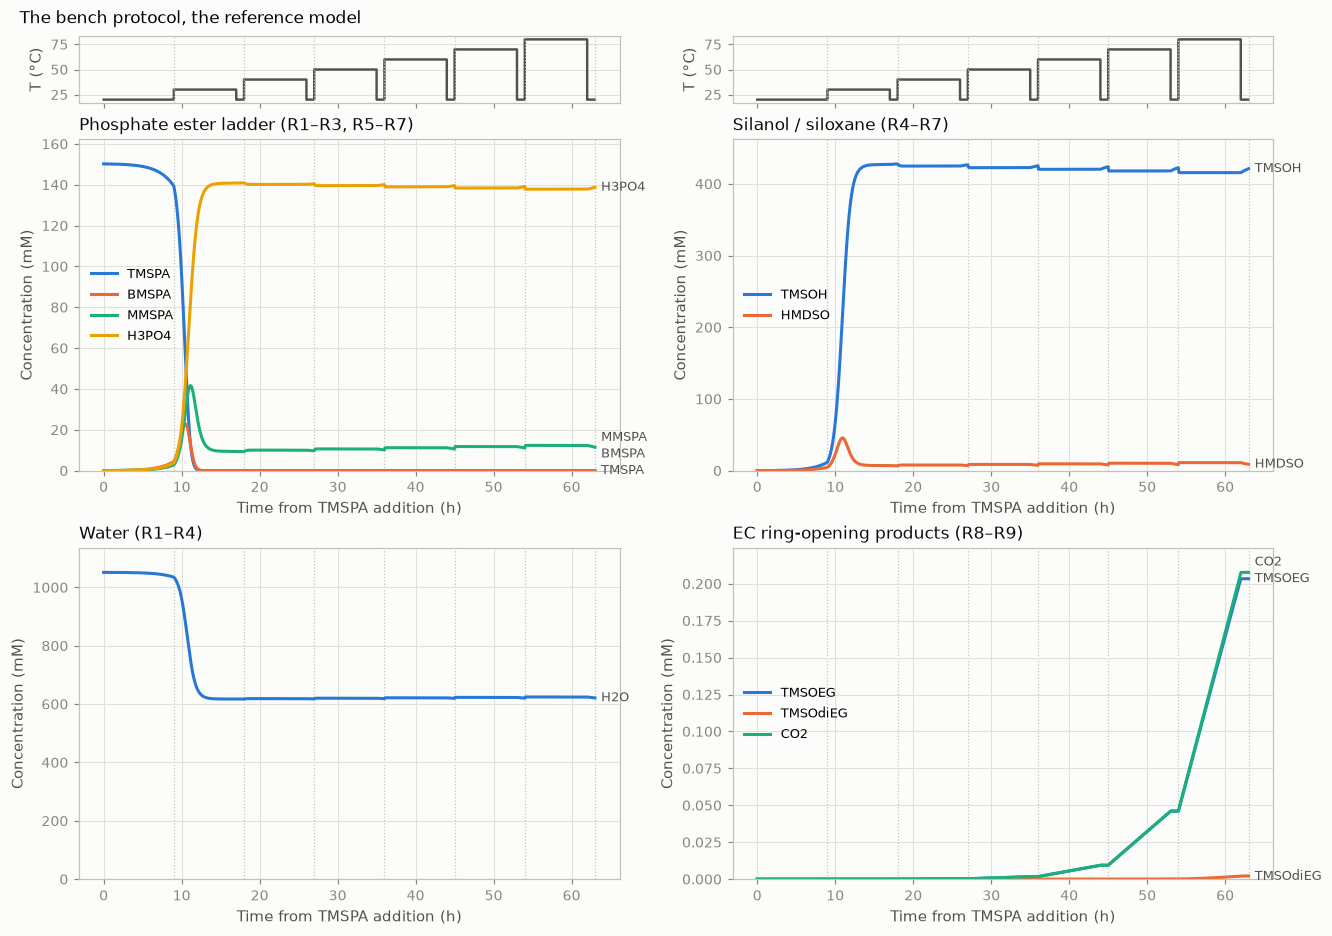

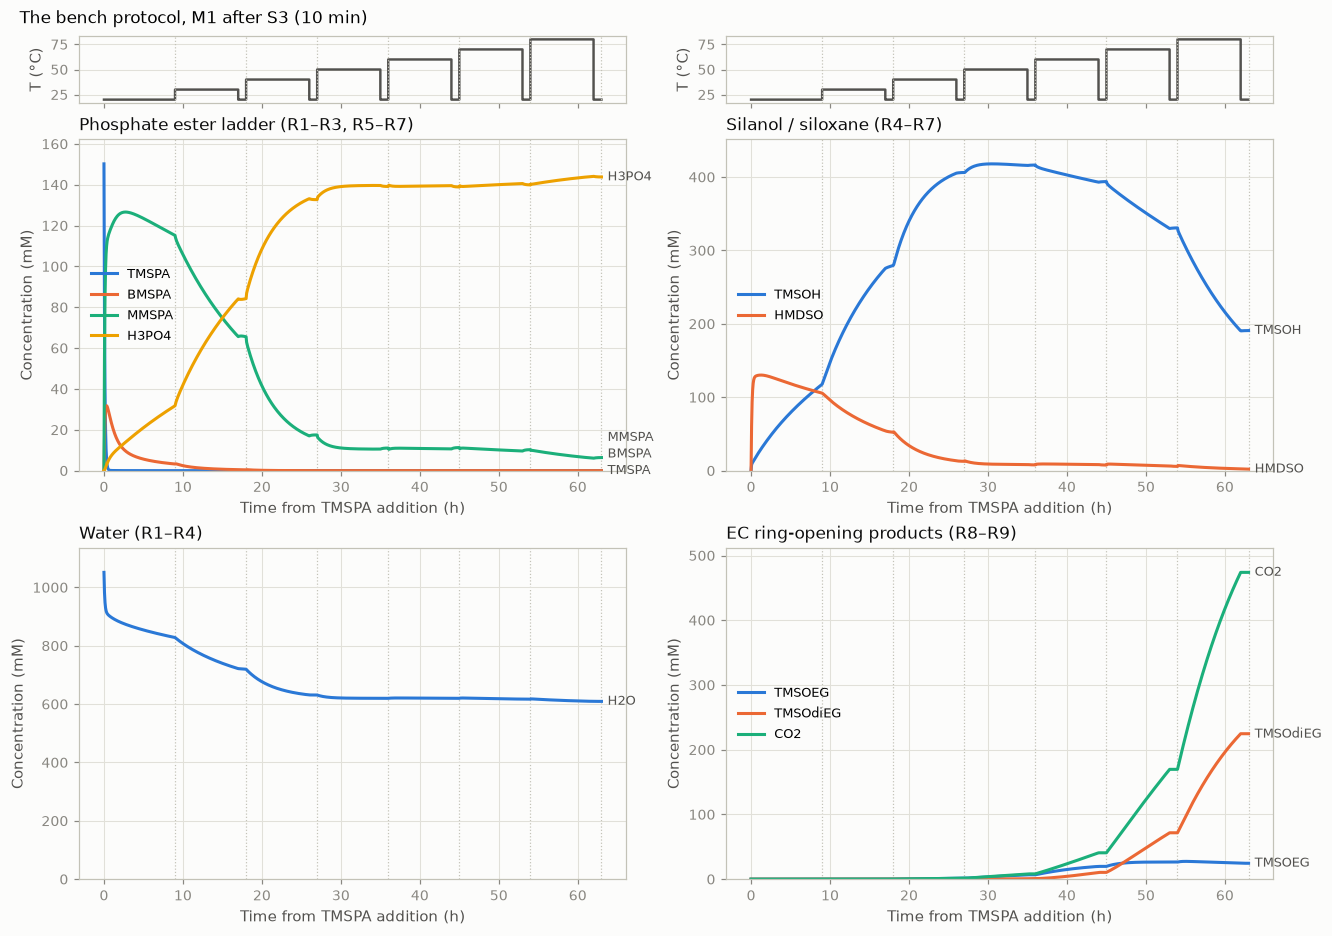

³¹P (% of P)                   ¹³C (% of Si)  \
                                        TMSPA BMSPA MMSPA H3PO4         TMSOH   
                     hold T (°C)                                                
the reference model  20.0                92.8   2.9   1.8   2.5           2.6   
                     30.0                 0.0   0.0   6.2  93.8          95.0   
                     40.0                 0.0   0.0   6.5  93.5          94.7   
                     50.0                 0.0   0.0   6.8  93.2          94.4   
                     60.0                 0.0   0.0   7.1  92.9          94.1   
                     70.0                 0.0   0.0   7.3  92.6          93.8   
                     80.0                 0.0   0.0   7.6  92.4          93.4   
M1 after S3 (10 min) 20.0                 0.0   2.2  76.7  21.2          26.1   
                     30.0                 0.0   0.3  43.6  56.1          62.0   
                     40.0                 0.0   0.0  11.6  88.3          90.2   
                     50.0                 0.0   0.0   7.4  92.6          92.4   
                     60.0                 0.0   0.0   7.5  92.5          87.4   
                     70.0                 0.0   0.0   6.8  93.2          73.4   
                     80.0                 0.0   0.0   4.3  95.7          42.3   

                                                      
                                 HMDSO TMSOEG + diEG  
                     hold T (°C)                      
the reference model  20.0          2.1           0.0  
                     30.0          3.0           0.0  
                     40.0          3.2           0.0  
                     50.0          3.4           0.0  
                     60.0          3.6           0.0  
                     70.0          3.8           0.0  
                     80.0          4.0           0.0  
M1 after S3 (10 min) 20.0         46.9           0.0  
                     30.0         23.2           0.0  
                     40.0          5.7           0.3  
                     50.0          3.5           1.7  
                     60.0          3.4           6.7  
                     70.0          2.6          21.7  
                     80.0          0.9          55.3

In [14]:
# The bench protocol of the reference model in EC:DEC 1:1: the neat-EC recipe with half its EC (DEC takes part in
# no step), its TMSPA density
recipe = calculate_recipe_molarities(densities_g_mL={**DEFAULT_DENSITY_G_ML, 'TMSPA': 0.945})
for stage in ('stock', 'after'):
    recipe[stage]['EC'] *= 0.5
bench = {'the reference model': with_network(REF_NETWORK, lambda: simulate_protocol(
             recipe=recipe, model=get_structure(REF_STRUCTURE).build(REF_BARRIERS)['model'])),
         f'{MAIN} after S3 ({SHOWN})': simulate_protocol(recipe=recipe, model=get_structure(MAIN).build(fits[('S3', SHOWN)]['theta'])['model'])}
for label, sim in bench.items():
    fig = plot_concentration_panels(sim, from_zero=True)
    fig.suptitle(f'The bench protocol, {label}', x=0.01, ha='left', fontsize=11)
    plt.show()


def tabulate_bench_shares(sim):
    # After each hold: the phosphorus and the silyl groups as the ³¹P and ¹³C spectra would share them (%)
    amounts = tabulate_acquisitions(sim)
    phosphorus = amounts[['TMSPA', 'BMSPA', 'MMSPA', 'H3PO4']]
    silyl = 3 * phosphorus['TMSPA'] + 2 * phosphorus['BMSPA'] + phosphorus['MMSPA'] + amounts['TMSOH'] + 2 * amounts['HMDSO'] + amounts['TMSOEG'] + amounts['TMSOdiEG']
    return pd.concat({'³¹P (% of P)': 100 * phosphorus.div(phosphorus.sum(axis=1), axis=0),
                      '¹³C (% of Si)': pd.DataFrame({'TMSOH': 100 * amounts['TMSOH'] / silyl, 'HMDSO': 200 * amounts['HMDSO'] / silyl,
                                                     'TMSOEG + diEG': 100 * (amounts['TMSOEG'] + amounts['TMSOdiEG']) / silyl})}, axis=1)


pd.concat({label: tabulate_bench_shares(sim) for label, sim in bench.items()}).round(1)

**What we see**

- **This code reproduces the reference notebook.** With its barriers, rule and classes, the composition after each hold matches the table of its network notebook to within 0.3 mM (93 % TMSPA left after the 20 °C hold, 94 % H₃PO₄ after the 30 °C hold, 0.2 mM of CO₂ after 80 °C). The small rest comes from its rounded k_BT/h. **The code is not the difference.**
- **The reference model, in time:** TMSPA survives the 8 h at 20 °C (93 % left) and falls all at once early in the 30 °C hold, about 10 h after mixing. The first products come slowly from water and TMSPA (R1, N15); the faster hydrolysis of BMSPA and MMSPA and the transfer then multiply TMSOH, and the fall comes all at once. The silyl groups end as TMSOH (93–95 %), and the solvent is not opened (solvent attack 1.40 eV).
- **M1 of S3, in the same protocol:** TMSPA is gone within minutes at 20 °C. The phosphate goes first to MMSPA (77 % after the 20 °C hold), then to H₃PO₄ through 30 and 40 °C. From 60 °C the TMSOH opens the solvent (55 % of the silyl groups after 80 °C).
- **Where they agree:** both end the phosphate at 92–96 % H₃PO₄ and keep almost no HMDSO. That is the end state of the computed energies, which the two share. Measured: 65 % H₃PO₄ and mostly HMDSO.

### 4.3 The reference model on our six tubes, one difference at a time

**The test:** its barriers scored on the six tubes as this project reads them (P0), then one of its choices changed at a time towards ours (P1–P5). Nothing is fitted.

| Case | What changes from the reference model |
|---|---|
| P0 | nothing: its rule, its classes, its barriers |
| P1 | Marcus instead of its rule (same barrier values) |
| P2 | N12 and N15 take the hydrolysis barriers of R2 and R1, as in M1 |
| P3 | R1 tied to R2/R3, at 0.96 eV |
| P4 | R1 tied to R2/R3, at 1.24 eV |
| P5 | Marcus and N12, N15 in hydrolysis together (M1's layout, its values) |

- **Table:** the worst miss of each tube, at each reading; the last column is `2 % H2O` as the reference model reads it.

In [15]:
cases = {'P0 reference model': (REF_STRUCTURE, REF_NETWORK, REF_BARRIERS),
         'P1 Marcus': ('M1-split', REF_NETWORK, REF_BARRIERS),
         'P2 N12, N15 in hydrolysis': (REF_STRUCTURE, CONFIG['network'], REF_BARRIERS),
         'P3 R1 with R2/R3 at 0.96': ('M1+BEP', REF_NETWORK, {'g hydrolysis': 0.96, **{k: v for k, v in REF_BARRIERS.items() if 'hydrolysis' not in k}}),
         'P4 R1 with R2/R3 at 1.24': ('M1+BEP', REF_NETWORK, {'g hydrolysis': 1.24, **{k: v for k, v in REF_BARRIERS.items() if 'hydrolysis' not in k}}),
         'P5 Marcus, N12, N15 in hydrolysis': ('M1-split', CONFIG['network'], REF_BARRIERS)}


def score_case(structure, network, theta):
    # Worst miss of every tube with one parameter set, nothing fitted: the six tubes at each reading, and 2 % H2O as the reference model reads it
    def score():
        rows = {}
        for scenario in READINGS:
            for label, overrides in (('', {}), ('2 % H2O, reference reading', REF_HISTORY)):
                for sample in build_sample_set(observables, scenario, paper=(), overrides=overrides):
                    if overrides and sample['name'] != '2 % H2O':
                        continue
                    table = FitProblem(structure, [sample], fixed=theta, solver=REPORT_SOLVER).table(np.zeros(0))
                    rows[(scenario, label or TUBE_NAMES[sample['name']])] = table['z'].abs().max()
        return pd.Series(rows)
    return with_network(network, score)


one_at_a_time = pd.DataFrame({case: score_case(*spec) for case, spec in cases.items()}).T
one_at_a_time.columns.names = ['reading', 'worst miss of']
one_at_a_time = one_at_a_time.reindex(columns=pd.MultiIndex.from_product([READINGS, list(TUBE_NAMES.values()) + ['2 % H2O, reference reading']]))
one_at_a_time.style.format(precision=1).map(lambda v: 'font-weight: bold' if v > 3.0 else '')

**What we see**

- **The reference model (P0) describes the two slow tubes at once:** `0.5 % H2O` (3.6 at 10 min) and `TMSPa alone` (3.0). M1 cannot (§2.4).
- **It misses the others:**
  - tube A at short ages (16.8 at 10 min, 4.7 at 8 h): its transfer is slow;
  - the glovebox (5.6, TMSOEG): its solvent attack, 1.40 eV, opens too little solvent;
  - the probe (6.0, HMDSO);
  - `2 % H2O`: 59.7 as this project reads it; 20.7 as the reference model reads it, on the TMSOH line of ¹³C, which that model never sees.
- **Which choice keeps `0.5 % H2O`:**
  - **Marcus instead of its rule (P1) loses it** (41.7). Marcus lowers the barrier of a downhill step: R1 goes from 1.24 to 1.12 eV, N15 from 1.15 to 0.99 eV;
  - **R1 tied to R2/R3 at 0.96 eV (P3) loses it too** (42);
  - **one slow hydrolysis at 1.24 eV for R1–R3 (P4) keeps it** (2.7), with `TMSPa alone` at 3.4;
  - **N12 and N15 in hydrolysis (P2) change little.**
  - What `0.5 % H2O` needs is a slow hydrolysis of TMSPA: an effective barrier of about 1.15–1.24 eV for R1 and N15. M1 fits `TMSPa alone` with hydrolysis g 1.06 eV, which with Marcus is a barrier of about 0.94 eV for R1: 0.3 eV faster.
- **`2 % H2O` as this project reads it fails in every case** at 10 min: whatever keeps `0.5 % H2O` leaves `2 % H2O` untouched minutes after mixing. Only the fast cases (P1, P5) finish it by 1 h, and they lose `0.5 % H2O`.

### 4.4 The figure that came close

**The question:** the reference model was shown close to the NMR of `2 % H2O`. With which energies?

- In the reference network notebook the database energies end the tube at about 94 % H₃PO₄, where 65 % is measured: the timing matches, the position of the R2/R3 equilibria does not. To reproduce the tube, ΔG(R2) and ΔG(R3) are calibrated there to −0.7 and −0.1 kcal/mol (a notebook not in this repository).
- **Figure:** the reference model with that calibration, on `2 % H2O` as it reads the tube, against the measured amounts (³¹P and ¹³C).

shift from the computed energies (eV): dG R1 +0.000, dG R4 +0.000, dG R2 +0.152, dG R3 +0.057


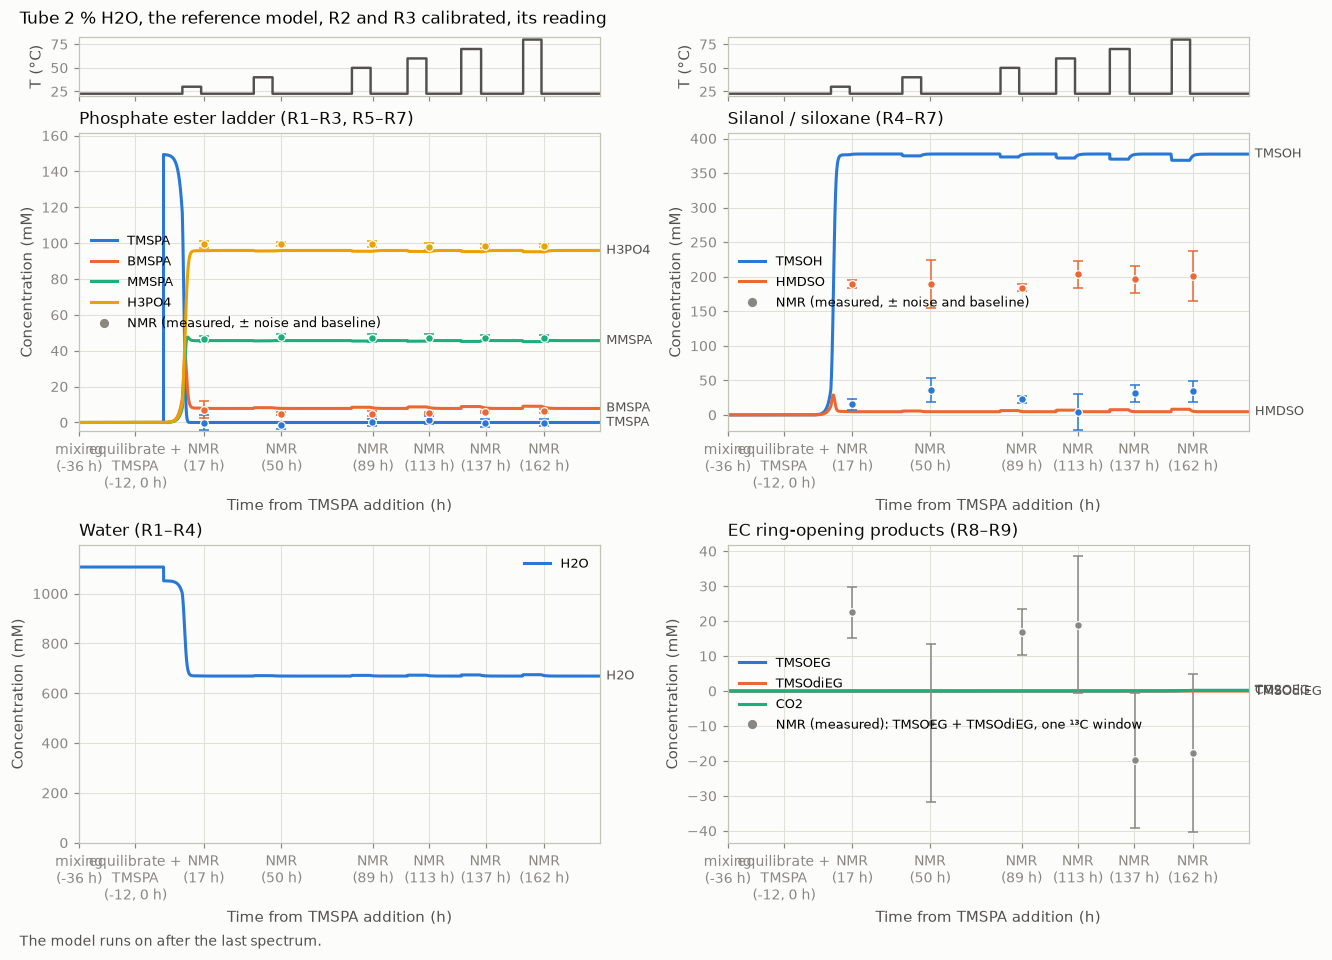

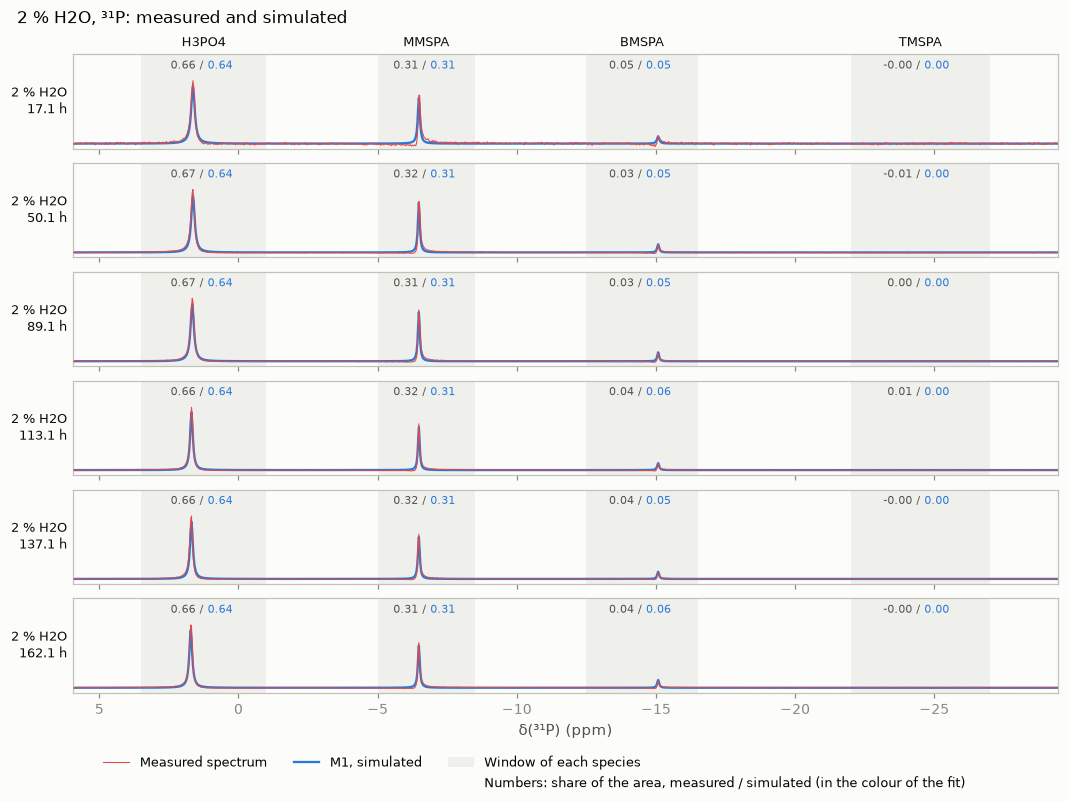

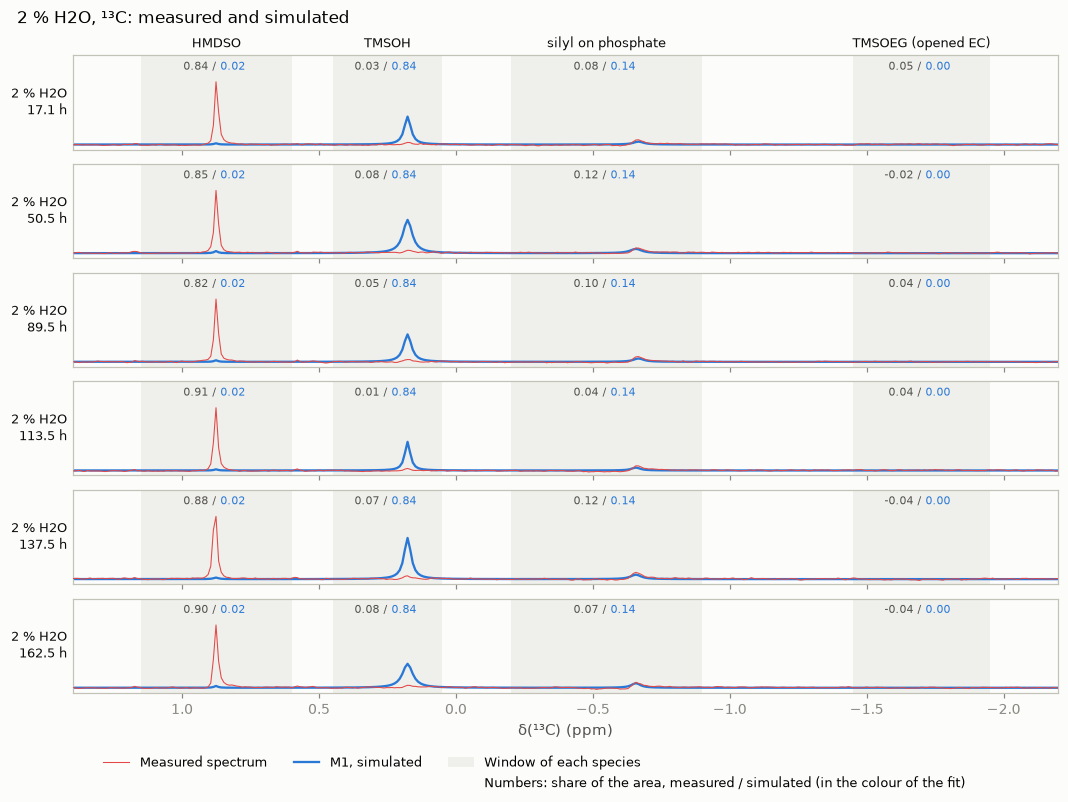

spectrum at (h),nucleus,species,NMR (mM),model (mM),Δy (mM),σ (mM),z (SD)
17.1,³¹P,TMSPA,-0.2,0.0,+0.2,3.48,+0.0
17.1,³¹P,BMSPA,7.1,7.9,+0.8,2.76,+0.3
17.1,³¹P,MMSPA,46.5,45.7,-0.8,3.48,-0.2
17.1,³¹P,H3PO4,99.3,95.8,-3.5,5.71,-0.6
17.1,¹³C,TMSOH,15.2,377.2,+362.0,24.43,+14.8
17.1,¹³C,HMDSO,378.3,9.5,-368.8,74.71,-4.9
17.1,¹³C,TMSOEG (opened EC),22.5,0.0,-22.5,28.69,-0.8
17.1,¹³C,silyl on phosphate,36.8,61.5,+24.7,29.45,+0.8
50.1,³¹P,TMSPA,-1.5,0.0,+1.5,2.57,+0.6
50.1,³¹P,BMSPA,5.0,7.9,+2.9,1.90,+1.5


In [16]:
calibrated = {**REF_BARRIERS, 'dG R1': 0.0, 'dG R4': 0.0, 'dG R2': -0.7 * KCAL_EV - (-0.182172), 'dG R3': -0.1 * KCAL_EV - (-0.060965)}
print('shift from the computed energies (eV): ' + ', '.join(f'{k} {v:+.3f}' for k, v in calibrated.items() if k.startswith('dG')))
ref_view = with_network(REF_NETWORK, lambda: evaluate_fit(as_fit('M3-split+BEP', calibrated), observables, overrides=REF_HISTORY))
show_concentrations(ref_view, '2 % H2O', 'the reference model, R2 and R3 calibrated, its reading',
                    note='First spectrum after 8 h at room temperature, 8 h at 30 °C and 1 h of acquisition (the reference reading).')

**What we see**

- **The calibration moves the energies:** R2 by +0.152 eV (1.6 standard errors of its solvent part) and R3 by +0.057 eV (0.7). That is a model with free energies (M3 or M5 here), not M1.
- **³¹P: the points sit on the curves** in all six spectra (H₃PO₄ 96 mM simulated against 98–100, MMSPA 46 against 47, BMSPA 8 against 5–7). This is the figure that came close.
- **¹³C of the same rounds: far off.** TMSOH about 377 mM simulated against 4–36 measured (worst miss 17), HMDSO about 10 against 370–410 (5). The silyl groups the reference model leaves as TMSOH are HMDSO in the tube. The energy of R4 (condensation) decides that, and it is not calibrated.

### 4.5 So what is different?

**Nothing in the code:** given the barriers, rule and classes of the reference model, this code gives its numbers (4.2). **Nothing in the energies:** they are the same values.

**What makes the results different:**

| | Effect | Where it shows |
|---|---|---|
| **The close figure of the reference model moves R2 and R3** (+0.15 and +0.06 eV) | the ³¹P of `2 % H2O` is reached; with the database energies the reference model ends at 94 % H₃PO₄, like ours | 4.2, 4.4 |
| **The reference model is compared on the ³¹P only** | the ¹³C of the same spectra shows HMDSO where both models keep TMSOH (the energy of R4) | 4.4 |
| **The time of the `2 % H2O` spectra** | the reference reading gives the tube 17 h, 8 of them at 30 °C, before its first spectrum, so a slow hydrolysis can finish it; the file clock puts that spectrum before any heating, minutes to hours after mixing, and then the tube asks for a fast hydrolysis | 1.4, 2.5, 4.3 |
| **The rule and classes of the reference model** | its hydrolysis of TMSPA is slow (R1 1.24 eV, N15 at 1.15 eV, flat for downhill steps); M1 (Marcus, R1 with R2/R3) makes it about 0.3 eV faster, and `0.5 % H2O` fails | 4.3 |
| **The reference model is fitted to one tube** | its barriers miss tube A at short ages, the glovebox and the probe, which M1 tube by tube describes | 2.1, 2.2, 4.3 |

**In short:** we are not doing it wrong. We hold the model to more data (six tubes, ¹³C, and the clock of the files). Where both see the same data (³¹P of `2 % H2O`) both give the same, as long as the energies are the same.

**What would decide between the two:**
- What "22oC after 3oC" means, and when TMSPA went into `2 % H2O`. Only the lab can say.
- The reference structure (R1 apart, N10–N15 at 1.15 eV, its rule) fitted tube by tube with the steps of §2. It runs in minutes with this code.

## 5. What can be said, and what cannot

**Can be said**

| What | Value | Rests on |
|---|---|---|
| Solvent attack | g = 1.21–1.24 eV | `TMSOH, glovebox`; confirmed by `TMSOH, probe`, never fitted (worst miss 1.3) |
| Condensation | g ≤ 1.25 eV (an upper limit) | `TMSOH, glovebox` |
| Transfer | g ≤ 0.92, 0.96 or 1.01 eV at 10 min, 1 h or 8 h (at least that fast) | `TMSPa + TMSOH (A)` |
| Hydrolysis (M1) | g = 1.04–1.10 eV at 10 min, 1.08–1.14 eV at 1 h | `TMSPa alone`, its water declared at 65.6 mM |
| This code and the reference model's | with the same inputs, the same results (to 0.3 mM) | 4.2 |
| The end of `2 % H2O` with the computed energies | 92–96 % H₃PO₄ and the silyl groups as TMSOH, in the reference model and in M1; measured 65 % H₃PO₄ and mostly HMDSO | 2.5, 4.2 |

**Cannot be said**

| Open point | Why | What would close it |
|---|---|---|
| One hydrolysis for every tube, with M1 | `0.5 % H2O` asks for about 1.25 eV, `TMSPa alone` for 1.04–1.14 eV (S4) | the reference layout (R1 slow, its rule), fitted tube by tube (4.3 suggests it can hold both) |
| `2 % H2O` with computed energies | under either reading it ends too hydrolysed, with TMSOH where HMDSO is measured | energies the tube may move (M5), checked on ¹³C as well as ³¹P |
| When `2 % H2O` was measured | the file names and the file clock disagree; the answer decides how fast hydrolysis must be | the lab notebook, or whoever ran the experiment |
| The age | 10 min and 1 h fit equally; 8 h fails only `TMSPa alone` | the mixing times |